# Car Price Prediction — Linear Regression

**Flow:** Imports → Load & inspect → Target analysis → Train/Test split → Helper functions & transformers
→ Feature-engineering checks → Preprocessing pipelines → EDA on preprocessed data → Feature selection
→ Scaler × Encoder search → Final model.

## 1. Imports

In [1]:
# ============================================================
# Import all required libraries (all imports live here)
# ============================================================
import re
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
from IPython.display import display

# Model selection & cross-validation utilities
from sklearn.model_selection import train_test_split, KFold, cross_val_score

# Pipeline & preprocessing tools
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import (
    FunctionTransformer, PowerTransformer,
    StandardScaler, RobustScaler, MinMaxScaler,
    OneHotEncoder, OrdinalEncoder, TargetEncoder
)
from sklearn.linear_model import LinearRegression
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# statsmodels is only needed for the VIF cell (section 8)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

## 2. Load the data & first look

In [2]:
# ============================================================
# Load the car details dataset
# ============================================================
df = pd.read_csv("car details v4.csv")

In [3]:
df.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null   float64
 16  Width 

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Make,2059,33,Maruti Suzuki,440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,2059,1050,X1 sDrive20d xLine,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,2059.0,NaN,NaN,NaN,1702991.696455,2419880.635434,49000.0,484999.0,825000.0,1925000.0,35000000.0
Year,2059.0,NaN,NaN,NaN,2016.425449,3.363564,1988.0,2014.0,2017.0,2019.0,2022.0
Kilometer,2059.0,NaN,NaN,NaN,54224.714424,57361.721314,0.0,29000.0,50000.0,72000.0,2000000.0
Fuel Type,2059,9,Diesel,1049,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,2059,2,Manual,1133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,2059,77,Mumbai,342,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Color,2059,17,White,802,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,2059,6,First,1619,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# ============================================================
# Print unique values for categorical columns
# (sorted alphabetically, strings only to avoid mixed-type errors)
# ============================================================
for col in ['Drivetrain', 'Seller Type', 'Owner', 'Color',
            'Location', 'Transmission', 'Fuel Type']:
    print(f"Unique values in column '{col}':")
    print(sorted(df[col].unique(), key=lambda x: str(x)))
    print("\n")

Unique values in column 'Drivetrain':
['AWD', 'FWD', 'RWD', nan]


Unique values in column 'Seller Type':
['Commercial Registration', 'Corporate', 'Individual']


Unique values in column 'Owner':
['4 or More', 'First', 'Fourth', 'Second', 'Third', 'UnRegistered Car']


Unique values in column 'Color':
['Beige', 'Black', 'Blue', 'Bronze', 'Brown', 'Gold', 'Green', 'Grey', 'Maroon', 'Orange', 'Others', 'Pink', 'Purple', 'Red', 'Silver', 'White', 'Yellow']


Unique values in column 'Location':
['Agra', 'Ahmedabad', 'Allahabad', 'Ambala Cantt', 'Amritsar', 'Aurangabad', 'Bangalore', 'Bhopal', 'Bhubaneswar', 'Bulandshahar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Dak. Kannada', 'Dehradun', 'Delhi', 'Deoghar', 'Dharwad', 'Ernakulam', 'Faizabad', 'Faridabad', 'Ghaziabad', 'Goa', 'Gorakhpur', 'Gurgaon', 'Guwahati', 'Haldwani', 'Hyderabad', 'Indore', 'Jaipur', 'Jalandhar', 'Jamshedpur', 'Kanpur', 'Karnal', 'Kharar', 'Kheda', 'Kolkata', 'Kollam', 'Kota', 'Lucknow', 'Ludhiana', 'Mangalore', 'Meer

In [7]:
# ============================================================
# Show unique car manufacturers
# ============================================================
print(sorted(df["Make"].unique(), key=lambda x: str(x)))

['Audi', 'BMW', 'Chevrolet', 'Datsun', 'Ferrari', 'Fiat', 'Ford', 'Honda', 'Hyundai', 'Isuzu', 'Jaguar', 'Jeep', 'Kia', 'Lamborghini', 'Land Rover', 'Lexus', 'MG', 'MINI', 'Mahindra', 'Maruti Suzuki', 'Maserati', 'Mercedes-Benz', 'Mitsubishi', 'Nissan', 'Porsche', 'Renault', 'Rolls-Royce', 'Skoda', 'Ssangyong', 'Tata', 'Toyota', 'Volkswagen', 'Volvo']


In [8]:
# ============================================================
# Check for duplicate rows
# ============================================================
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [9]:
# ============================================================
# Summarize missing values (count + percentage + dtype)
# ============================================================
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": df.isna().mean() * 100,
    "Data_Type": df.dtypes.astype(str)
})
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage", ascending=False
)
missing_summary

,Missing_Count,Missing_Percentage,Data_Type
Drivetrain,136,6.605148,object
Fuel Tank Capacity,113,5.488101,float64
Max Torque,80,3.885381,object
Max Power,80,3.885381,object
Engine,80,3.885381,object
Seating Capacity,64,3.108305,float64
Height,64,3.108305,float64
Width,64,3.108305,float64
Length,64,3.108305,float64
Model,0,0.000000,object


In [10]:
# ============================================================
# Group rows by their MISSING pattern
# (helps decide whether to drop rows or impute)
# ============================================================
missing_mask = df.isna()
missing_count = missing_mask.sum(axis=1)
rows_with_missing = missing_mask.loc[missing_count > 0]

missing_patterns = (
    rows_with_missing
    .groupby(list(rows_with_missing.columns), dropna=False)
    .size()
    .reset_index(name="Number of Rows")
)

missing_patterns["Missing Columns"] = missing_patterns.apply(
    lambda row: [c for c in rows_with_missing.columns if row[c]],
    axis=1
)
missing_patterns["Number of Missing Columns"] = (
    missing_patterns["Missing Columns"].str.len()
)

missing_patterns = (
    missing_patterns[
        ["Number of Missing Columns", "Missing Columns", "Number of Rows"]
    ]
    .sort_values(["Number of Missing Columns", "Number of Rows"],
                 ascending=[False, False])
    .reset_index(drop=True)
)

display(missing_patterns)

,Number of Missing Columns,Missing Columns,Number of Rows
0,9,"[Engine, Max Power, Max Torque, Drivetrain, Le...",64
1,4,"[Engine, Max Power, Max Torque, Drivetrain]",9
2,4,"[Engine, Max Power, Max Torque, Fuel Tank Capa...",7
3,1,[Drivetrain],63
4,1,[Fuel Tank Capacity],42


## 3. Features / target and Price distribution

In [11]:
# ============================================================
# Separate features (X) from target (y)
# - Drop rows where Price is missing (none in this dataset)
# ============================================================
df_clean = df.dropna(subset=["Price"]).copy()
print("Rows dropped due to missing Price:", len(df) - len(df_clean))

X = df_clean.drop(columns=["Price"])
y = df_clean["Price"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Rows dropped due to missing Price: 0
Features shape: (2059, 19)
Target shape: (2059,)


TARGET (Price) — RAW STATISTICS
Mean      : 1,702,992
Median    : 825,000
Std       : 2,419,881
Skewness  : 4.965   (>1 = strongly right-skewed)
Kurtosis  : 40.298


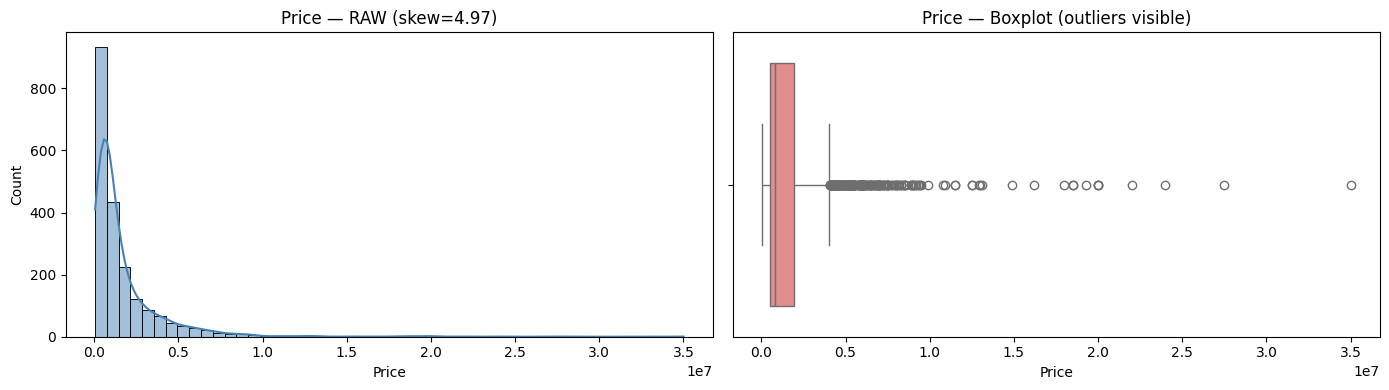

In [12]:
# ============================================================
# Analyze Price (target) distribution — RAW
# ============================================================
# Questions we answer here:
#   1. Is Price skewed? (skewness > 1 = yes)
#   2. Are there extreme outliers? (Lamborghini, Rolls-Royce)
#   3. Should we transform it before training?
# ============================================================
print("=" * 55)
print("TARGET (Price) — RAW STATISTICS")
print("=" * 55)
print(f"Mean      : {y.mean():,.0f}")
print(f"Median    : {y.median():,.0f}")
print(f"Std       : {y.std():,.0f}")
print(f"Skewness  : {y.skew():.3f}   (>1 = strongly right-skewed)")
print(f"Kurtosis  : {y.kurtosis():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(y, bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title(f"Price — RAW (skew={y.skew():.2f})")
axes[0].set_xlabel("Price")

sns.boxplot(x=y, ax=axes[1], color='lightcoral')
axes[1].set_title("Price — Boxplot (outliers visible)")

plt.tight_layout()
plt.show()

Skewness BEFORE log1p: 4.965
Skewness AFTER  log1p: 0.486


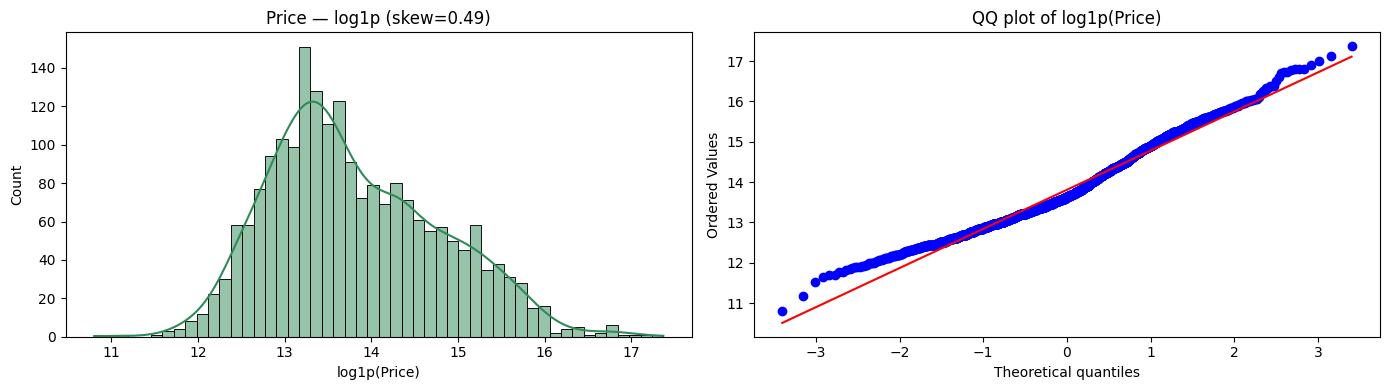


✅ Price is right-skewed → log1p is justified.
   We'll train on log1p(Price) and inverse with expm1.


In [13]:
# ============================================================
# CELL 12: Does log1p help normalize Price?
# ============================================================
# We compare skewness BEFORE and AFTER log1p.
# If log1p significantly reduces skewness → use it in the model.
# ============================================================
y_log = np.log1p(y)
print(f"Skewness BEFORE log1p: {y.skew():.3f}")
print(f"Skewness AFTER  log1p: {y_log.skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(y_log, bins=50, kde=True, ax=axes[0], color='seagreen')
axes[0].set_title(f"Price — log1p (skew={y_log.skew():.2f})")
axes[0].set_xlabel("log1p(Price)")

stats.probplot(y_log, dist="norm", plot=axes[1])
axes[1].set_title("QQ plot of log1p(Price)")

plt.tight_layout()
plt.show()

if abs(y.skew()) > 1 and abs(y_log.skew()) < abs(y.skew()):
    print("\n✅ Price is right-skewed → log1p is justified.")
    print("   We'll train on log1p(Price) and inverse with expm1.")
else:
    print("\nℹ️  Price is not heavily skewed — log1p may not help.")

## 4. Train / Test split

In [14]:
# ============================================================
# Split data into 80% train / 20% test
# random_state=42 → reproducible split
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (1647, 19)
Testing Features: (412, 19)
Training Target: (1647,)
Testing Target: (412,)


In [15]:
# ============================================================
# Compare missing values in Train vs Test
# (should be roughly similar proportions if split is random)
# ============================================================
missing_train = pd.DataFrame({
    "Missing_Count": X_train.isnull().sum(),
    "Missing_Percentage": X_train.isnull().mean() * 100
})
missing_test = pd.DataFrame({
    "Missing_Count": X_test.isnull().sum(),
    "Missing_Percentage": X_test.isnull().mean() * 100
})

missing_summary = pd.DataFrame({
    "Train_Missing_Count": missing_train["Missing_Count"],
    "Train_Missing_Percentage": missing_train["Missing_Percentage"],
    "Test_Missing_Count": missing_test["Missing_Count"],
    "Test_Missing_Percentage": missing_test["Missing_Percentage"]
})
missing_summary = missing_summary.sort_values(
    by="Train_Missing_Percentage", ascending=False
)
display(missing_summary.round(2))

,Train_Missing_Count,Train_Missing_Percentage,Test_Missing_Count,Test_Missing_Percentage
Drivetrain,111,6.74,25,6.07
Fuel Tank Capacity,90,5.46,23,5.58
Engine,65,3.95,15,3.64
Max Torque,65,3.95,15,3.64
Max Power,65,3.95,15,3.64
Seating Capacity,52,3.16,12,2.91
Height,52,3.16,12,2.91
Width,52,3.16,12,2.91
Length,52,3.16,12,2.91
Make,0,0.00,0,0.00


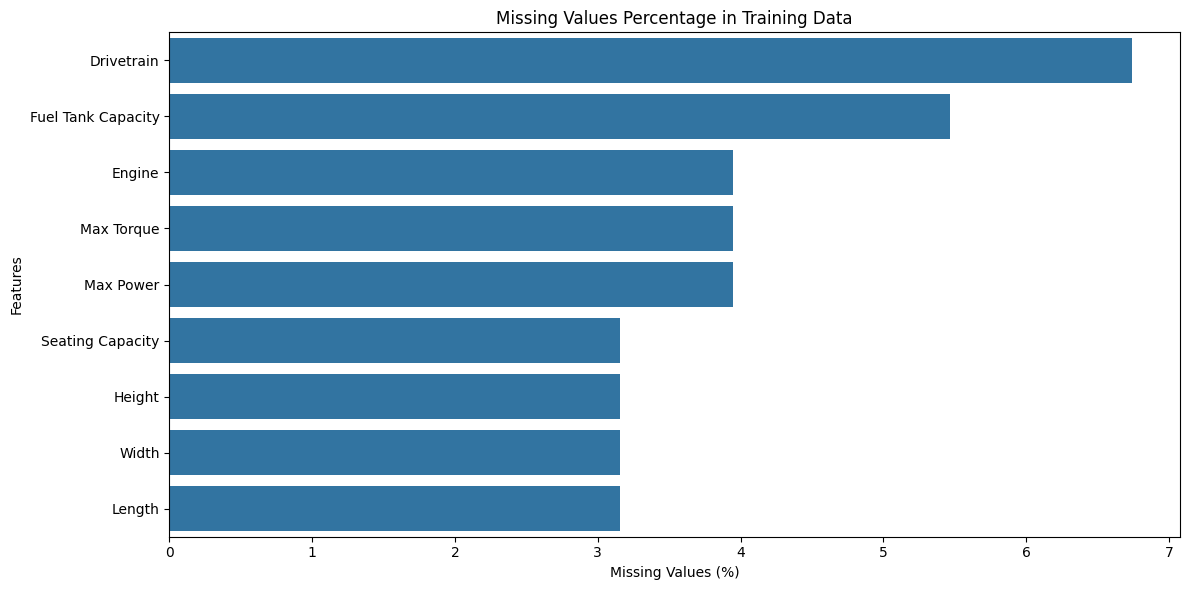

In [16]:
# ============================================================
# Bar chart of missing values in TRAIN set
# ============================================================
missing_plot = (
    X_train.isnull().mean().mul(100)
    .sort_values(ascending=False)
)
missing_plot = missing_plot[missing_plot > 0]

plt.figure(figsize=(12, 6))
sns.barplot(x=missing_plot.values, y=missing_plot.index)
plt.title("Missing Values Percentage in Training Data")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [17]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1647 entries, 266 to 860
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                1647 non-null   object 
 1   Model               1647 non-null   object 
 2   Year                1647 non-null   int64  
 3   Kilometer           1647 non-null   int64  
 4   Fuel Type           1647 non-null   object 
 5   Transmission        1647 non-null   object 
 6   Location            1647 non-null   object 
 7   Color               1647 non-null   object 
 8   Owner               1647 non-null   object 
 9   Seller Type         1647 non-null   object 
 10  Engine              1582 non-null   object 
 11  Max Power           1582 non-null   object 
 12  Max Torque          1582 non-null   object 
 13  Drivetrain          1536 non-null   object 
 14  Length              1595 non-null   float64
 15  Width               1595 non-null   float64
 16  Height    

## 5. Helper functions & custom transformers
Only **definitions** here (nothing is fitted yet), so every later cell can use them.

### 5.1 Row-level cleaning helpers

In [18]:
# ============================================================
# Kilometer outliers
# ------------------------------------------------------------
# - drop_high_kilometer : DELETES rows (TRAIN ONLY, done outside the
#                         pipeline because a pipeline step must never
#                         change the number of rows / break X-y alignment).
# - cap_kilometer       : row-preserving cap, used INSIDE the pipeline so
#                         test / new data with absurd mileage still works.
# ============================================================
def drop_high_kilometer(X, y, threshold=500_000):
    """Delete rows where Kilometer > threshold from BOTH X and y."""
    if "Kilometer" not in X.columns:
        print("'Kilometer' not found - skipping.")
        return X, y
    mask = ~(X["Kilometer"] > threshold)          # NaN is kept
    print(f"Kilometer > {threshold:,}: dropped {int((~mask).sum())} rows")
    return X.loc[mask].copy(), y.loc[mask].copy()


def cap_kilometer(X, threshold=500_000):
    """Cap Kilometer at `threshold` (keeps all rows)."""
    X = X.copy()
    if "Kilometer" in X.columns:
        X["Kilometer"] = X["Kilometer"].clip(upper=threshold)
    return X

In [19]:
# ============================================================
# Drop rows that had >= 9 original missing fields
# (likely junk rows with almost no info)
# ============================================================
def prepare_rows(X, y, threshold=9):
    X = X.copy()
    X["_original_missing_count"] = X.isna().sum(axis=1)
    mask = X["_original_missing_count"] < threshold
    X_clean = X.loc[mask].drop(columns=["_original_missing_count"]).copy()
    y_clean = y.loc[X_clean.index].copy()
    print(f"Dropped: {int((~mask).sum())} | Kept: {int(mask.sum())}")
    return X_clean, y_clean

### 5.2 Feature engineering & model-string imputation

In [20]:
# ============================================================
# Custom feature engineering
# Creates:
#   - car_age       = current year - year
#   - km_per_year   = Kilometer / car_age
#   - engine_cc     = numeric cc extracted from "Engine" text
#   - power_bhp     = numeric bhp from "Max Power" text
#   - power_rpm     = rpm value from "Max Power" text
#   - torque_nm     = numeric Nm from "Max Torque" text
#   - torque_rpm    = rpm value from "Max Torque" text
#   - Volume        = Length × Width × Height
# ============================================================
def feature_engineering(X):
    X = X.copy()
    CURRENT_YEAR = 2026

    # 1. Car age
    X["car_age"] = CURRENT_YEAR - X["Year"]

    # 2. Kilometers per year (clip to avoid division by zero)
    X["km_per_year"] = X["Kilometer"] / X["car_age"].clip(lower=1)

    # 3. Engine capacity in cc
    engine_text = X["Engine"].astype("string")
    engine_cc = engine_text.str.extract(
        r"(\d+(?:\.\d+)?)\s*cc\b", flags=re.IGNORECASE
    )[0]
    X["engine_cc"] = pd.to_numeric(engine_cc, errors="coerce")

    # 4. Maximum power (bhp) and its RPM
    power_text = X["Max Power"].astype("string")
    power = power_text.str.extract(
        r"^\s*([\d.]+)\s*(?:bhp|BHP|PS|HP)?\s*@\s*([\d,]+)?",
        flags=re.IGNORECASE
    )
    X["power_bhp"] = pd.to_numeric(power[0], errors="coerce")
    X["power_rpm"] = pd.to_numeric(
        power[1].str.replace(",", "", regex=False), errors="coerce"
    )

    # 5. Maximum torque (Nm) and its RPM
    torque_text = X["Max Torque"].astype("string")
    torque = torque_text.str.extract(
        r"^\s*([\d.]+)\s*(?:Nm|N\.m|kgm|kg-m)?\s*@\s*([\d,]+)?",
        flags=re.IGNORECASE
    )
    X["torque_nm"] = pd.to_numeric(torque[0], errors="coerce")
    X["torque_rpm"] = pd.to_numeric(
        torque[1].str.replace(",", "", regex=False), errors="coerce"
    )

    # 6. Volume = Length × Width × Height
    X["Volume"] = X["Length"] * X["Width"] * X["Height"]

    return X

In [21]:
# ============================================================
# Impute missing values by parsing the "Model" string
# (e.g., "1.2L" → engine_cc=1200, "quattro" → AWD, "7 STR" → 7 seats)
# ============================================================
def impute_from_model(X, report=False):
    X = X.copy()
    X["_original_missing_count"] = X.isna().sum(axis=1)
    model = X["Model"].astype("string").fillna("")

    target_columns = [c for c in [
        "engine_cc", "power_bhp", "torque_nm",
        "Drivetrain", "Seating Capacity", "Fuel Type"
    ] if c in X.columns]

    missing_before = X[target_columns].isna().sum()

    # Force numeric columns to accept floats
    for col in ["engine_cc", "power_bhp", "torque_nm", "Seating Capacity"]:
        if col in X.columns:
            X[col] = pd.to_numeric(X[col], errors="coerce").astype("float64").astype("float64")

    # 1. Engine capacity from Model (handles both "1.2 L" and "1200 cc")
    if "engine_cc" in X.columns:
        engine_match = model.str.extract(
            r"\b(\d+(?:\.\d+)?)\s*(L|cc)\b|\b(\d+\.\d+)\b",
            flags=re.IGNORECASE
        )
        engine_value  = pd.to_numeric(engine_match[0].fillna(engine_match[2]),
                                       errors="coerce").astype("float64")
        engine_unit   = engine_match[1].str.lower()
        engine_candidate = engine_value.where(
            engine_unit.eq("cc").fillna(False).astype(bool), engine_value * 1000
        )
        bare_decimal = engine_match[0].isna() & engine_match[2].notna()
        engine_candidate = engine_candidate.mask(bare_decimal)

        fill_mask = (
            X["engine_cc"].isna() & engine_candidate.notna()
            & engine_candidate.between(500, 10000)
        )
        X.loc[fill_mask, "engine_cc"] = engine_candidate.loc[fill_mask]

    # 2. Max power (bhp) — convert PS → BHP by ×0.98632
    if "power_bhp" in X.columns:
        power_match = model.str.extract(
            r"\b(\d+(?:\.\d+)?)\s*(bhp|ps|hp)\b", flags=re.IGNORECASE
        )
        power_value = pd.to_numeric(power_match[0], errors="coerce").astype("float64")
        power_unit  = power_match[1].str.lower()
        power_candidate = power_value.where(
            power_unit.ne("ps").fillna(True).astype(bool), power_value * 0.98632
        )
        fill_mask = (
            X["power_bhp"].isna() & power_candidate.notna()
            & power_candidate.between(20, 2000)
        )
        X.loc[fill_mask, "power_bhp"] = power_candidate.loc[fill_mask]

    # 3. Max torque (Nm)
    if "torque_nm" in X.columns:
        torque_match = model.str.extract(
            r"\b(\d+(?:\.\d+)?)\s*(Nm|N\.m)\b", flags=re.IGNORECASE
        )
        torque_candidate = pd.to_numeric(torque_match[0], errors="coerce").astype("float64")
        fill_mask = (
            X["torque_nm"].isna() & torque_candidate.notna()
            & torque_candidate.between(20, 5000)
        )
        X.loc[fill_mask, "torque_nm"] = torque_candidate.loc[fill_mask]

    # 4. Drivetrain from brand keywords
    if "Drivetrain" in X.columns:
        drivetrain_patterns = [
            (r"\bAWD\b", "AWD"), (r"\bFWD\b", "FWD"), (r"\bRWD\b", "RWD"),
            (r"\bquattro\b", "AWD"), (r"\bxDrive\b", "AWD"),
            (r"\b4MATIC\b", "AWD"), (r"\b4x4\b", "AWD"),
        ]
        drivetrain_candidate = pd.Series(pd.NA, index=X.index, dtype="string")
        for pattern, value in drivetrain_patterns:
            matches = model.str.contains(pattern, case=False, regex=True,
                                          na=False)
            drivetrain_candidate.loc[
                matches & drivetrain_candidate.isna()
            ] = value
        fill_mask = X["Drivetrain"].isna() & drivetrain_candidate.notna()
        X.loc[fill_mask, "Drivetrain"] = drivetrain_candidate.loc[fill_mask]

    # 5. Seating capacity from "7 STR" etc.
    if "Seating Capacity" in X.columns:
        seating_match = model.str.extract(
            r"\b([2-9])\s*(?:STR|Seaters?|Seats)\b", flags=re.IGNORECASE
        )
        seating_candidate = pd.to_numeric(seating_match[0], errors="coerce").astype("float64")
        fill_mask = (X["Seating Capacity"].isna()
                     & seating_candidate.notna())
        X.loc[fill_mask, "Seating Capacity"] = seating_candidate.loc[fill_mask]

    # 6. Fuel type from explicit names
    if "Fuel Type" in X.columns:
        fuel_patterns = [(r"\bDiesel\b", "Diesel"), (r"\bPetrol\b", "Petrol")]
        fuel_candidate = pd.Series(pd.NA, index=X.index, dtype="string")
        for pattern, value in fuel_patterns:
            matches = model.str.contains(pattern, case=False, regex=True,
                                          na=False)
            fuel_candidate.loc[matches & fuel_candidate.isna()] = value
        fill_mask = X["Fuel Type"].isna() & fuel_candidate.notna()
        X.loc[fill_mask, "Fuel Type"] = fuel_candidate.loc[fill_mask]

    # Missing report
    missing_after = X[target_columns].isna().sum()
    report_df = pd.DataFrame({
        "Missing_Before": missing_before,
        "Missing_After":  missing_after,
        "Values_Filled":  missing_before - missing_after
    })

    if report:
        print("\n" + "=" * 55)
        print("MISSING VALUES REPORT")
        print("=" * 55)
        display(report_df)

    return X

In [22]:
# ============================================================
# Drop raw text columns after extracting features
# (Year dropped too since we now have car_age)
# ============================================================
def drop_original_columns(X):
    X = X.copy()
    columns_to_drop = [
        "Engine", "Max Power", "Max Torque",
        "Year", "_original_missing_count"
    ]
    X = X.drop(
        columns=[c for c in columns_to_drop if c in X.columns],
        errors="ignore"
    )
    return X

In [23]:
# ============================================================
# Drop power_rpm and torque_rpm (highly correlated with
# their Nm/bhp counterparts, add noise more than signal)
# ============================================================
def drop_rpm_features(X):
    X = X.copy()
    columns_to_drop = ["power_rpm", "torque_rpm"]
    return X.drop(
        columns=[col for col in columns_to_drop if col in X.columns]
    )

In [24]:
# ============================================================
# Drop redundant / weak features (decided in section 8 from the
# correlation + VIF analysis). Kept as a pipeline step so the
# saved pipeline accepts RAW data.
#   - Keep Volume, drop Length / Width / Height
#   - Keep power_bhp, drop engine_cc / torque_nm
#   - Keep km_per_year, drop Kilometer
#   - Drop Seating Capacity (|r| < 0.05)
# ============================================================
REDUNDANT_COLS = [
    "Length", "Width", "Height",
    "torque_nm", "engine_cc",
    "Kilometer",
    "Seating Capacity",
]

def drop_redundant_columns(X):
    return X.drop(columns=[c for c in REDUNDANT_COLS if c in X.columns])

### 5.3 Model-name cleaning & group imputers

In [25]:
# ============================================================
# Normalize the "Model" string:
#   - remove year ranges like "[2017-2019]"
#   - unify dashes and spacing
#   - merge "xDrive 30d" → "xdrive30d"
# Result: 912 → 871 unique models (fewer = better encoding)
# ============================================================
def clean_model(X, report=True):
    X = X.copy()
    original = X["Model"].astype("string")
    model = original.str.lower()

    # 1. Remove year ranges [2016-2020]
    model = model.str.replace(
        r"\s*\[\s*\d{4}(?:\s*-\s*\d{4})?\s*\]", "", regex=True
    )
    # 2. Normalize dash characters
    model = model.str.replace(r"[‐-‒–—]", "-", regex=True)
    # 3. Normalize spaces around "+"
    model = model.str.replace(r"\s*\+\s*", " + ", regex=True)
    # 4. Collapse repeated whitespace
    model = model.str.replace(r"\s+", " ", regex=True).str.strip()
    # 5. Merge BMW drive designations
    model = model.str.replace(r"\b(xdrive|sdrive)\s+(\d)", r"\1\2", regex=True)
    # 6. Final cleanup
    model = model.str.replace(r"\s+", " ", regex=True).str.strip()

    X["Model_clean"] = model
    X = X.drop(columns=["Model"])

    if report:
        print("=" * 65)
        print("MODEL CLEANING REPORT")
        print("=" * 65)
        print(f"Unique models before: {original.nunique(dropna=True)}")
        print(f"Unique models after:  {model.nunique(dropna=True)}")
        print("Reduction in unique categories:",
              original.nunique(dropna=True) - model.nunique(dropna=True))
    return X

In [26]:
# ============================================================
# Custom Transformer — impute missing values using
# median (numeric) or mode (categorical) grouped by Make+Model.
# Only uses groups with >= min_group_size samples (avoids noise).
# ============================================================
class ModelMakeImputer(BaseEstimator, TransformerMixin):

    def __init__(self, min_group_size=3, report=True):
        self.min_group_size = min_group_size
        self.report = report
        self.numeric_cols = [
            "engine_cc", "power_bhp", "power_rpm",
            "torque_nm", "torque_rpm",
            "Length", "Width", "Height", "Seating Capacity",
            "Volume", "Fuel Tank Capacity"
        ]
        self.categorical_cols = ["Drivetrain"]

    @staticmethod
    def get_statistic(series, numeric=True):
        values = series.dropna()
        if values.empty:
            return np.nan
        if numeric:
            return values.median()
        modes = values.mode()
        return modes.iloc[0] if not modes.empty else np.nan

    def fit(self, X, y=None):
        X = X.copy()
        self.numeric_cols_ = [c for c in self.numeric_cols if c in X.columns]
        self.categorical_cols_ = [c for c in self.categorical_cols if c in X.columns]

        for col in self.numeric_cols_:
            X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

        self.group_stats_ = {}
        if {"Make", "Model_clean"}.issubset(X.columns):
            for col in self.numeric_cols_:
                self.group_stats_[col] = X.groupby(
                    ["Make", "Model_clean"], dropna=False
                )[col].agg(["median", "count"])
            for col in self.categorical_cols_:
                self.group_stats_[col] = X.groupby(
                    ["Make", "Model_clean"], dropna=False
                )[col].agg(
                    mode=lambda s: self.get_statistic(s, numeric=False),
                    count="count"
                )
        return self

    def transform(self, X):
        X = X.copy()
        report_rows = []

        for col in self.numeric_cols_:
            X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

        for col in self.numeric_cols_ + self.categorical_cols_:
            missing_before = int(X[col].isna().sum())
            filled = 0

            if col in self.group_stats_ and \
               {"Make", "Model_clean"}.issubset(X.columns):
                stats = self.group_stats_[col]
                for idx in X.index[X[col].isna()]:
                    key = (X.at[idx, "Make"], X.at[idx, "Model_clean"])
                    if key not in stats.index:
                        continue
                    row = stats.loc[key]
                    if row["count"] < self.min_group_size:
                        continue
                    stat_name = ("median" if col in self.numeric_cols_
                                 else "mode")
                    value = row[stat_name]
                    if pd.notna(value):
                        X.at[idx, col] = value
                        filled += 1

            report_rows.append({
                "Feature": col, "Missing_Before": missing_before,
                "Filled_From_Model_Make": filled,
                "Missing_After": int(X[col].isna().sum())
            })

        self.report_ = pd.DataFrame(report_rows)
        if self.report:
            print("\nMODEL + MAKE IMPUTATION REPORT")
            display(self.report_)
        return X

In [27]:
# ============================================================
# Fallback imputer — tries Model→Make→Global for
# any values still missing after Cell 25.
# ============================================================
class GroupBasedImputer(BaseEstimator, TransformerMixin):

    def __init__(self, min_group_size=3, report=True):
        self.min_group_size = min_group_size
        self.report = report
        self.numeric_cols = [
            "engine_cc", "power_bhp", "power_rpm",
            "torque_nm", "torque_rpm",
            "Length", "Width", "Height", "Seating Capacity",
            "Volume", "Fuel Tank Capacity"
        ]
        self.categorical_cols = ["Drivetrain"]

    @staticmethod
    def get_statistic(series, numeric=True):
        values = series.dropna()
        if values.empty:
            return np.nan
        if numeric:
            return values.median()
        modes = values.mode()
        return modes.iloc[0] if not modes.empty else np.nan

    def fit(self, X, y=None):
        X = X.copy()
        self.numeric_cols_ = [c for c in self.numeric_cols if c in X.columns]
        self.categorical_cols_ = [c for c in self.categorical_cols if c in X.columns]

        for col in self.numeric_cols_:
            X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

        self.global_values_, self.make_values_, self.model_values_ = {}, {}, {}

        # Global fallback
        for col in self.numeric_cols_:
            self.global_values_[col] = self.get_statistic(X[col], True)
        for col in self.categorical_cols_:
            self.global_values_[col] = self.get_statistic(X[col], False)

        # Make-level stats
        if "Make" in X.columns:
            for col in self.numeric_cols_:
                self.make_values_[col] = X.groupby("Make")[col].median()
            for col in self.categorical_cols_:
                self.make_values_[col] = X.groupby("Make")[col].agg(
                    lambda s: self.get_statistic(s, False)
                )

        # Make+Model stats
        if {"Make", "Model_clean"}.issubset(X.columns):
            groups = ["Make", "Model_clean"]
            for col in self.numeric_cols_:
                self.model_values_[col] = X.groupby(groups)[col].agg(
                    ["median", "count"]
                )
            for col in self.categorical_cols_:
                self.model_values_[col] = X.groupby(groups)[col].agg(
                    mode=lambda s: self.get_statistic(s, False),
                    count="count"
                )
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.numeric_cols_:
            X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

        report_rows = []
        for col in self.numeric_cols_ + self.categorical_cols_:
            missing_before = int(X[col].isna().sum())
            filled_model = filled_make = filled_global = 0
            numeric = col in self.numeric_cols_

            # 1. Model group
            if col in self.model_values_ and \
               {"Make", "Model_clean"}.issubset(X.columns):
                stats = self.model_values_[col]
                for idx in X.index[X[col].isna()]:
                    key = (X.at[idx, "Make"], X.at[idx, "Model_clean"])
                    if key not in stats.index:
                        continue
                    row = stats.loc[key]
                    if row["count"] < self.min_group_size:
                        continue
                    value = row["median" if numeric else "mode"]
                    if pd.notna(value):
                        X.at[idx, col] = value
                        filled_model += 1

            # 2. Make group
            if col in self.make_values_ and "Make" in X.columns:
                stats = self.make_values_[col]
                for idx in X.index[X[col].isna()]:
                    make = X.at[idx, "Make"]
                    if make not in stats.index:
                        continue
                    value = stats.loc[make]
                    if pd.notna(value):
                        X.at[idx, col] = value
                        filled_make += 1

            # 3. Global fallback
            fallback = self.global_values_.get(col, np.nan)
            if pd.notna(fallback):
                mask = X[col].isna()
                filled_global = int(mask.sum())
                X.loc[mask, col] = fallback

            report_rows.append({
                "Feature": col, "Missing_Before": missing_before,
                "Filled_Model_Group": filled_model,
                "Filled_Make_Group":  filled_make,
                "Filled_Global":      filled_global,
                "Missing_Final":      int(X[col].isna().sum())
            })

        self.report_ = pd.DataFrame(report_rows)
        if self.report:
            print("\nFINAL GROUP-BASED IMPUTATION REPORT")
            display(self.report_)
        return X

### 5.4 Yeo-Johnson, scaler and categorical encoder

In [28]:
# ============================================================
# Yeo-Johnson transformer (works with negative values too)
# Normalizes numeric features without affecting the target
# ============================================================
class YeoJohnsonTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.numeric_columns_ = [
            c for c in X.select_dtypes(include=["number"]).columns
            if c != "Price"
        ]
        self.transformer_ = PowerTransformer(
            method="yeo-johnson", standardize=False
        )
        if self.numeric_columns_:
            self.transformer_.fit(X[self.numeric_columns_])
        return self

    def transform(self, X):
        X = X.copy()
        if self.numeric_columns_:
            X[self.numeric_columns_] = self.transformer_.transform(
                X[self.numeric_columns_]
            )
        return X

In [29]:
# ============================================================
# Scaler that fits on TRAIN only, applies to TEST
# (avoids data leakage)
# ============================================================
class NumericScaler(BaseEstimator, TransformerMixin):
    def __init__(self, exclude=('Price',), scaler=None):
        self.exclude = exclude
        self.scaler = scaler

    def fit(self, X, y=None):
        X = X.copy()
        cols = X.select_dtypes(include='number').columns.tolist()
        self.columns_ = [c for c in cols if c not in self.exclude]
        base = self.scaler if self.scaler is not None else RobustScaler()
        self.scaler_ = clone(base)
        if self.columns_:
            self.scaler_.fit(X[self.columns_])
        return self

    def transform(self, X):
        X = X.copy()
        if getattr(self, "columns_", None):
            X[self.columns_] = self.scaler_.transform(X[self.columns_])
        return X

In [30]:
# ============================================================
# One-Hot Encoder that handles unseen categories
# (handle_unknown='ignore' → unknowns become all-zeros)
# ============================================================
class CategoricalEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols, drop_cols=None, encoder=None):
        self.cat_cols = cat_cols
        self.drop_cols = drop_cols or []
        self.encoder = encoder

    def fit(self, X, y=None):
        X = X.copy()
        for c in self.drop_cols:
            X = X.drop(columns=c, errors='ignore')
        self.cat_cols_ = [c for c in self.cat_cols if c in X.columns]
        base = self.encoder if self.encoder is not None else OneHotEncoder(
            drop='first', sparse_output=False, handle_unknown='ignore'
        )
        self.encoder_ = clone(base)
        if self.cat_cols_:
            self.encoder_.fit(X[self.cat_cols_])
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.drop_cols:
            X = X.drop(columns=c, errors='ignore')
        if getattr(self, "cat_cols_", None):
            enc = self.encoder_.transform(X[self.cat_cols_])
            enc_df = pd.DataFrame(
                enc,
                columns=self.encoder_.get_feature_names_out(self.cat_cols_),
                index=X.index
            )
            X = X.drop(columns=self.cat_cols_)
            X = pd.concat([X, enc_df], axis=1)
        return X

## 6. Feature-engineering checks (exploration only)

In [31]:
# ============================================================
# Check correlation between the 4 extracted features
# (bhp, rpm, Nm, rpm) to decide whether to keep both RPM columns
# ============================================================
power = X_train["Max Power"].astype("string").str.extract(
    r"([\d.]+)\s*bhp\s*@\s*([\d,]+)", flags=0
)
torque = X_train["Max Torque"].astype("string").str.extract(
    r"([\d.]+)\s*Nm\s*@\s*([\d,]+)", flags=0
)

power_bhp  = pd.to_numeric(power[0], errors="coerce")
power_rpm  = pd.to_numeric(power[1].str.replace(",", "", regex=False),
                            errors="coerce")
torque_nm  = pd.to_numeric(torque[0], errors="coerce")
torque_rpm = pd.to_numeric(torque[1].str.replace(",", "", regex=False),
                            errors="coerce")

relationship_df = pd.DataFrame({
    "power_bhp": power_bhp, "power_rpm": power_rpm,
    "torque_nm": torque_nm, "torque_rpm": torque_rpm
})

display(relationship_df.corr().round(3))
print("Power and torque available together:",
      relationship_df[["power_bhp", "torque_nm"]].dropna().shape[0])
print("Power RPM and torque RPM available together:",
      relationship_df[["power_rpm", "torque_rpm"]].dropna().shape[0])

,power_bhp,power_rpm,torque_nm,torque_rpm
power_bhp,1.000,-0.291,0.882,-0.416
power_rpm,-0.291,1.000,-0.642,0.848
torque_nm,0.882,-0.642,1.000,-0.660
torque_rpm,-0.416,0.848,-0.660,1.000


Power and torque available together: 1475
Power RPM and torque RPM available together: 1475


In [32]:
# ============================================================
# Validate that feature engineering extracted values
# correctly (i.e., only missing when original was missing)
# ============================================================
X_train_fe = feature_engineering(X_train)
X_test_fe  = feature_engineering(X_test)

source_columns = {
    "engine_cc": "Engine",
    "power_bhp": "Max Power",
    "torque_nm": "Max Torque"
}

for new_col, original_col in source_columns.items():
    print(f"\n{'=' * 15} {new_col} {'=' * 15}")
    original_missing = X_train[original_col].isna()
    feature_missing  = X_train_fe[new_col].isna()

    print("Missing in original column:", original_missing.sum())
    print("Missing in new feature:",    feature_missing.sum())
    print("Original value exists, but extraction failed:",
          (original_missing.eq(False) & feature_missing).sum())

    print("\nExamples where extraction failed:")
    failed_rows = X_train.loc[
        ~original_missing & feature_missing,
        ["Make", "Model", original_col]
    ]
    display(failed_rows.head(10))


=============== engine_cc ===============
Missing in original column: 65
Missing in new feature: 65
Original value exists, but extraction failed: 0

Examples where extraction failed:


,Make,Model,Engine



=============== power_bhp ===============
Missing in original column: 65
Missing in new feature: 65
Original value exists, but extraction failed: 0

Examples where extraction failed:


,Make,Model,Max Power



=============== torque_nm ===============
Missing in original column: 65
Missing in new feature: 65
Original value exists, but extraction failed: 0

Examples where extraction failed:


,Make,Model,Max Torque


In [33]:
# ============================================================
# Apply model-based imputation to train and test
# (report=True to see what got filled)
# ============================================================
# impute_from_model works on the engineered columns (engine_cc, power_bhp, ...),
# so it must be applied AFTER feature_engineering (this is the order used in the pipeline).
X_train_model = impute_from_model(X_train_fe, report=True)
X_test_model  = impute_from_model(X_test_fe,  report=True)


MISSING VALUES REPORT


,Missing_Before,Missing_After,Values_Filled
engine_cc,65,61,4
power_bhp,65,64,1
torque_nm,65,65,0
Drivetrain,111,107,4
Seating Capacity,52,51,1
Fuel Type,0,0,0



MISSING VALUES REPORT


,Missing_Before,Missing_After,Values_Filled
engine_cc,15,14,1
power_bhp,15,13,2
torque_nm,15,15,0
Drivetrain,25,24,1
Seating Capacity,12,12,0
Fuel Type,0,0,0


In [34]:
# ============================================================
# Explore top-5 most frequent models per Make
# (helps decide if "Model" is too high-cardinality)
# ============================================================
model_frequencies = X_train["Model"].value_counts().sort_values(
    ascending=False
)

all_models = (
    X_train[["Make", "Model"]].drop_duplicates()
    .sort_values(by=["Make", "Model"], ascending=[True, True])
    .reset_index(drop=True)
)

for make, group in all_models.groupby("Make", sort=True):
    print(f"\n{'=' * 80}")
    print(f"MAKE: {make.upper()}")
    print(f"Number of models: {group['Model'].nunique()}")
    print("=" * 80)
    display(
        group.merge(
            model_frequencies.rename("Frequency"),
            left_on="Model", right_index=True, how="left"
        )
        .sort_values(by="Frequency", ascending=False)
        .head(5)
        .reset_index(drop=True)
    )


MAKE: AUDI
Number of models: 55


,Make,Model,Frequency
0,Audi,A6 35 TDI Matrix,10
1,Audi,Q3 35 TDI Premium + Sunroof,7
2,Audi,A6 2.0 TDI Premium,5
3,Audi,A3 35 TDI Premium,4
4,Audi,Q7 45 TDI Premium Plus,4



MAKE: BMW
Number of models: 41


,Make,Model,Frequency
0,BMW,X1 sDrive20d xLine,14
1,BMW,5-Series 520d Luxury Line [2017-2019],6
2,BMW,3-Series 320d Luxury Line,5
3,BMW,X3 xDrive 20d Luxury Line [2018-2020],4
4,BMW,5-Series 530d M Sport [2013-2017],4



MAKE: CHEVROLET
Number of models: 4


...

,Make,Model,Frequency
0,Toyota,Fortuner 2.8 4x2 AT [2016-2020],12
1,Toyota,Fortuner 2.8 4x4 AT [2016-2020],7
2,Toyota,Fortuner 3.0 4x4 MT,5
3,Toyota,Innova 2.8 ZX AT 7 STR [2016-2020],5
4,Toyota,Fortuner 3.0 4x2 AT,5



MAKE: VOLKSWAGEN
Number of models: 25


,Make,Model,Frequency
0,Volkswagen,Polo Comfortline 1.2L (P),4
1,Volkswagen,Polo GT TSI,3
2,Volkswagen,Vento Highline Plus 1.2 (P) AT 16 Alloy,2
3,Volkswagen,Vento Comfortline Petrol,2
4,Volkswagen,Polo Highline1.2L (D),2



MAKE: VOLVO
Number of models: 9


,Make,Model,Frequency
0,Volvo,V40 D3 R-Design,5
1,Volvo,S60 Kinetic D4,1
2,Volvo,S90 D4 Inscription,1
3,Volvo,S90 Momentum D4 [2018-2020],1
4,Volvo,V40 Cross Country D3,1


## 7. Preprocessing pipelines (A keeps RPM features, B drops them)

In [35]:
# ============================================================
# Preprocessing pipeline factory (row-preserving steps only)
#   A: keeps power_rpm / torque_rpm      B: drops them
# ============================================================
def make_preprocess(drop_rpm=False):
    steps = [
        ("cap_kilometer",       FunctionTransformer(cap_kilometer, validate=False)),
        ("feature_engineering", FunctionTransformer(feature_engineering, validate=False)),
        ("impute_from_model",   FunctionTransformer(impute_from_model, validate=False)),
        ("clean_model",         FunctionTransformer(clean_model, kw_args={"report": False},
                                                    validate=False)),
        ("model_make_imputer",  ModelMakeImputer(min_group_size=3, report=False)),
        ("final_group_imputer", GroupBasedImputer(min_group_size=3, report=False)),
        ("drop_original_cols",  FunctionTransformer(drop_original_columns, validate=False)),
    ]
    if drop_rpm:
        steps.append(("drop_rpm", FunctionTransformer(drop_rpm_features, validate=False)))
    return Pipeline(steps)

preprocess_a = make_preprocess(drop_rpm=False)
preprocess_b = make_preprocess(drop_rpm=True)

In [36]:
# ============================================================
# Prepare train (drop bad rows) and test (keep as-is)
# Note: test kept as-is → imputation handles missing values
# ============================================================
X_train_clean, y_train_clean = prepare_rows(X_train, y_train)
# Delete absurd-mileage rows from TRAIN only (test is capped inside the pipeline instead)
X_train_clean, y_train_clean = drop_high_kilometer(X_train_clean, y_train_clean,
                                                   threshold=500_000)
X_test_clean = X_test.copy()
y_test_clean = y_test.copy()

print("Train:", X_train_clean.shape, y_train_clean.shape)
print("Test :", X_test_clean.shape,  y_test_clean.shape)

Dropped: 52 | Kept: 1595
Kilometer > 500,000: dropped 1 rows
Train: (1594, 19) (1594,)
Test : (412, 19) (412,)


In [37]:
# ============================================================
# Fit preprocessing A / B on TRAIN, transform TEST
# ============================================================
X_train_a = preprocess_a.fit_transform(X_train_clean, y_train_clean)
X_test_a  = preprocess_a.transform(X_test_clean)

X_train_b = preprocess_b.fit_transform(X_train_clean, y_train_clean)
X_test_b  = preprocess_b.transform(X_test_clean)

print("A:", X_train_a.shape, X_test_a.shape)
print("B:", X_train_b.shape, X_test_b.shape)
print("Remaining NaNs in A (train):")
print(X_train_a.isna().sum()[lambda s: s > 0])

A: (1594, 23) (412, 23)
B: (1594, 21) (412, 21)
Remaining NaNs in A (train):
Series([], dtype: int64)


In [38]:
# ============================================================
# Align y with X using the SAME index
# (important if any pipeline step dropped rows)
# ============================================================
y_train_a = y_train_clean.loc[X_train_a.index].copy()
y_train_b = y_train_clean.loc[X_train_b.index].copy()
y_test_a  = y_test_clean.loc[X_test_a.index].copy()
y_test_b  = y_test_clean.loc[X_test_b.index].copy()

## 8. EDA on the preprocessed training data

In [39]:
# ============================================================
# Feature skewness report (BEFORE transformation)
# ============================================================
# For each numeric feature we show:
#   - Skewness value (>1 = needs transformation)
#   - Min/Max (extreme values?)
# ============================================================
numeric_features = [
    c for c in X_train_a.select_dtypes(include='number').columns
    if c != 'Price'
]

skew_rows = []
for col in numeric_features:
    s = X_train_a[col].dropna()
    skew_rows.append({
        "Feature":  col,
        "Skewness": s.skew(),
        "Min":      s.min(),
        "Max":      s.max(),
        "IQR":      s.quantile(0.75) - s.quantile(0.25),
    })

skew_df = pd.DataFrame(skew_rows).sort_values(
    "Skewness", key=abs, ascending=False
)

print("=" * 60)
print("FEATURE SKEWNESS (|skew| > 1 → needs transformation)")
print("=" * 60)
print(skew_df.round(2).to_string(index=False))

FEATURE SKEWNESS (|skew| > 1 → needs transformation)
           Feature  Skewness          Min          Max          IQR
       km_per_year      3.24          0.0 5.500000e+04 3.532710e+03
         power_bhp      2.02         35.0 6.020000e+02 8.800000e+01
         Kilometer      1.88          0.0 4.400000e+05 4.346925e+04
         engine_cc      1.87        624.0 6.592000e+03 7.980000e+02
  Seating Capacity      1.54          2.0 8.000000e+00 0.000000e+00
         torque_nm      0.89         48.0 7.800000e+02 2.350000e+02
            Height      0.86       1165.0 1.995000e+03 1.900000e+02
           car_age      0.82          4.0 3.800000e+01 5.000000e+00
Fuel Tank Capacity      0.79         15.0 1.050000e+02 2.100000e+01
            Volume      0.57 7461361250.0 2.123688e+10 3.359275e+09
        torque_rpm      0.53       1200.0 6.500000e+03 2.400000e+03
             Width      0.30       1475.0 2.220000e+03 1.400000e+02
         power_rpm      0.20       2910.0 8.250000e+03 2.000000

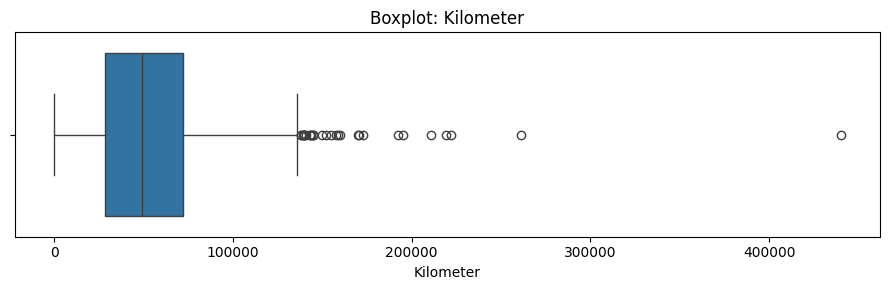

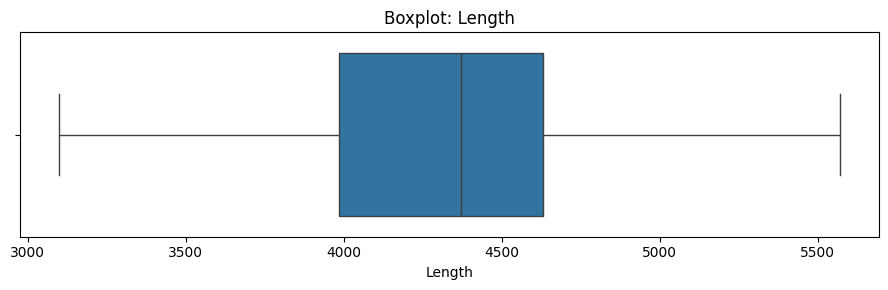

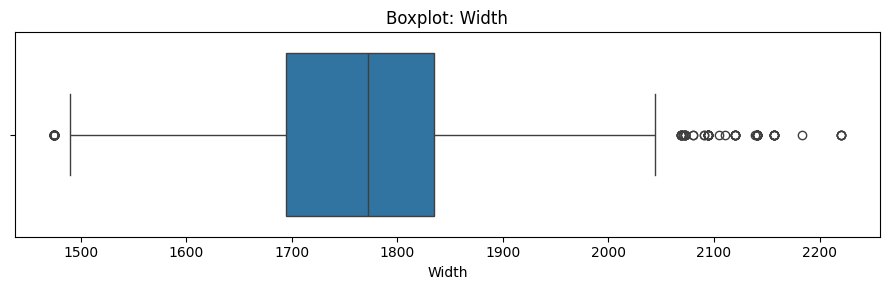

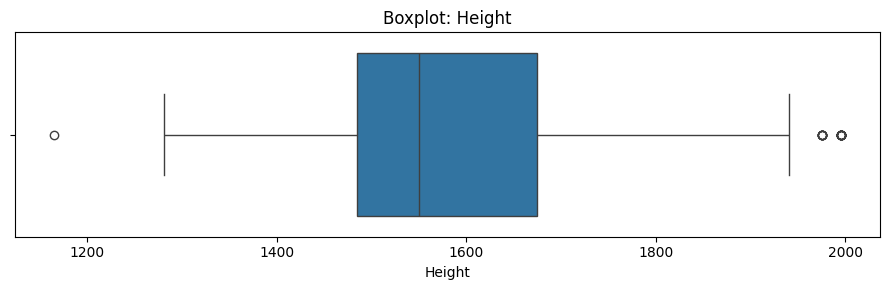

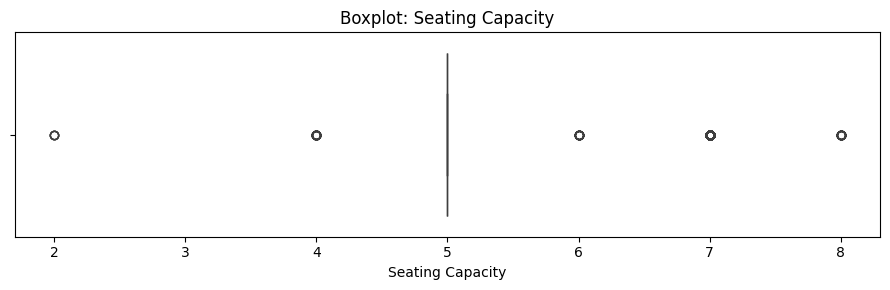

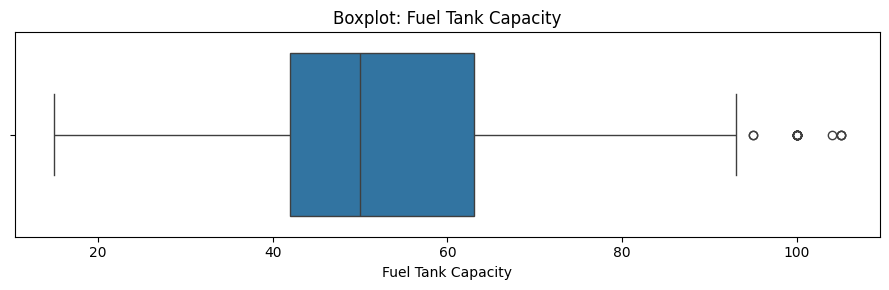

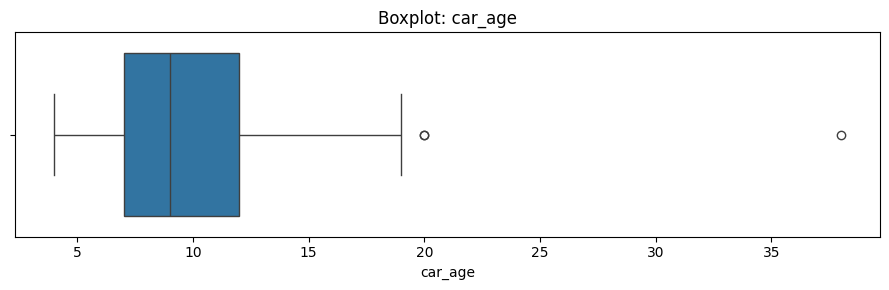

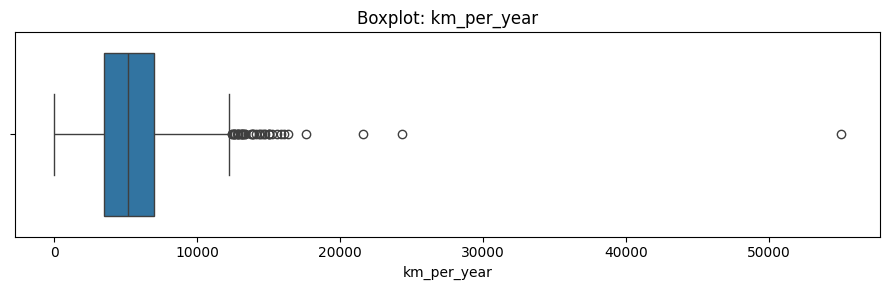

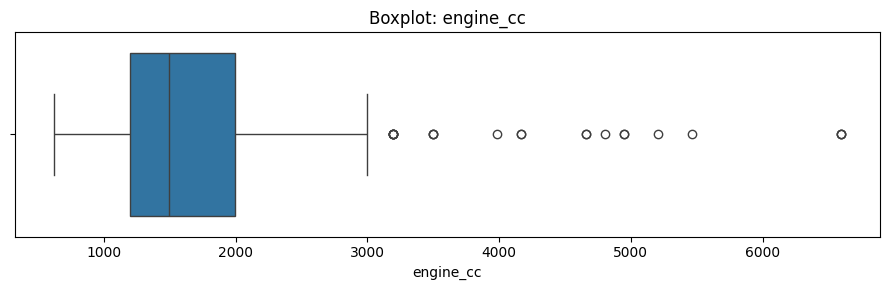

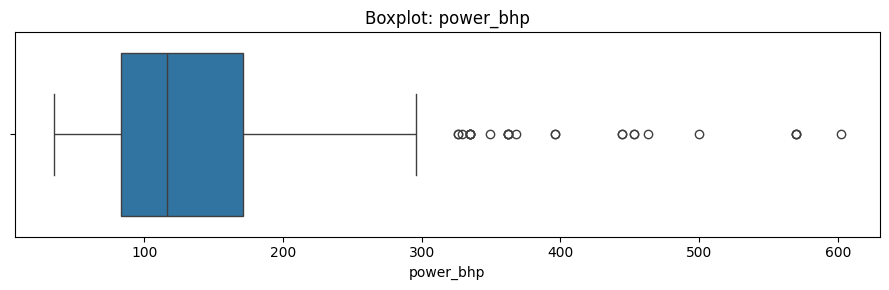

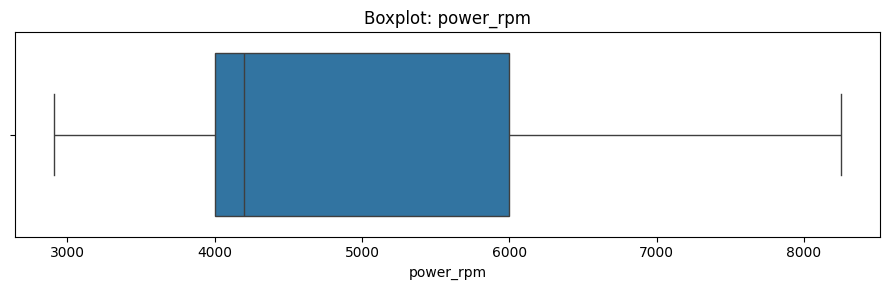

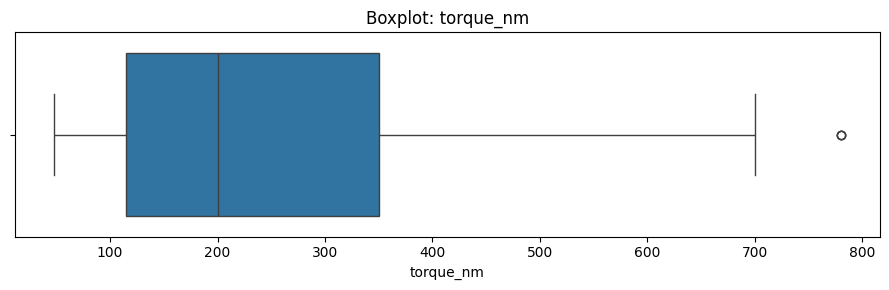

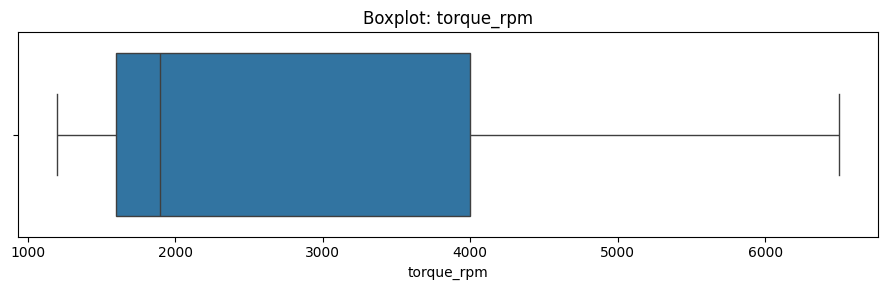

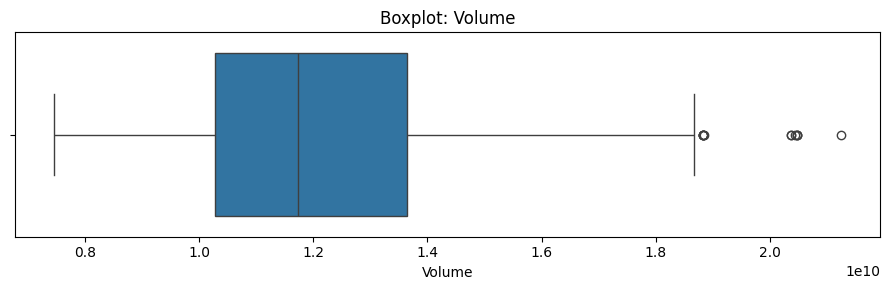

In [40]:
# ============================================================
# Boxplots for all numeric features (spot outliers)
# ============================================================
for col in numeric_features:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=X_train_a[col])
    plt.title(f"Boxplot: {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

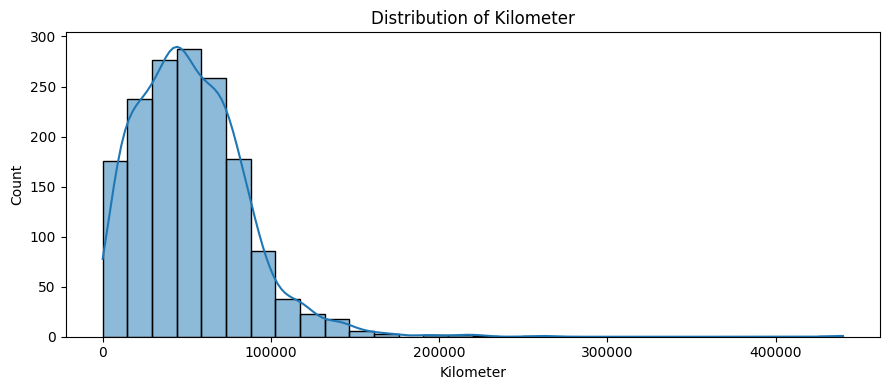

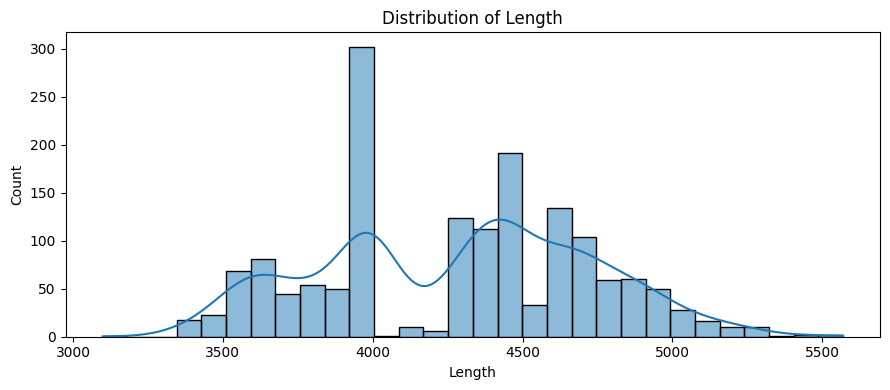

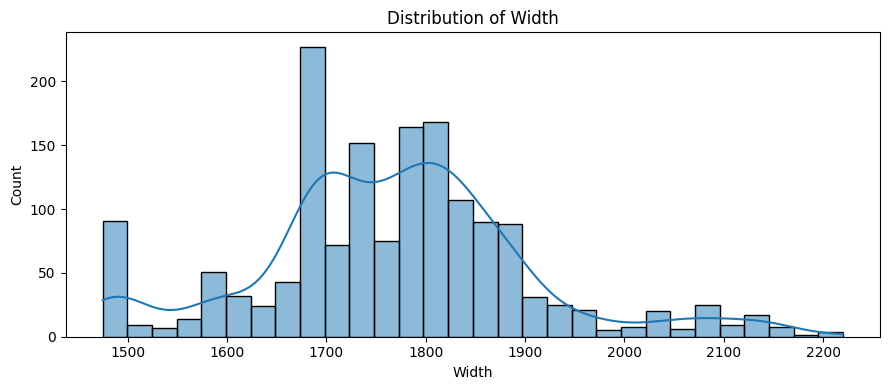

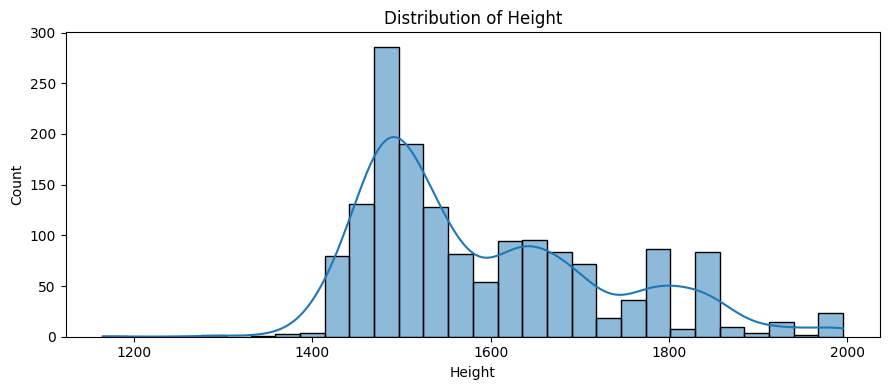

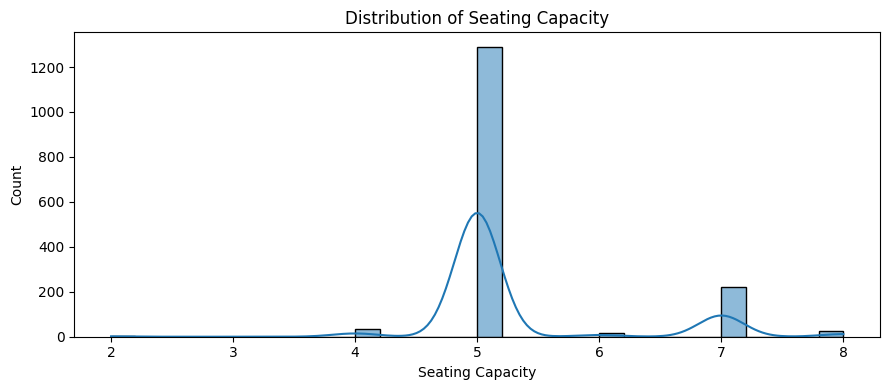

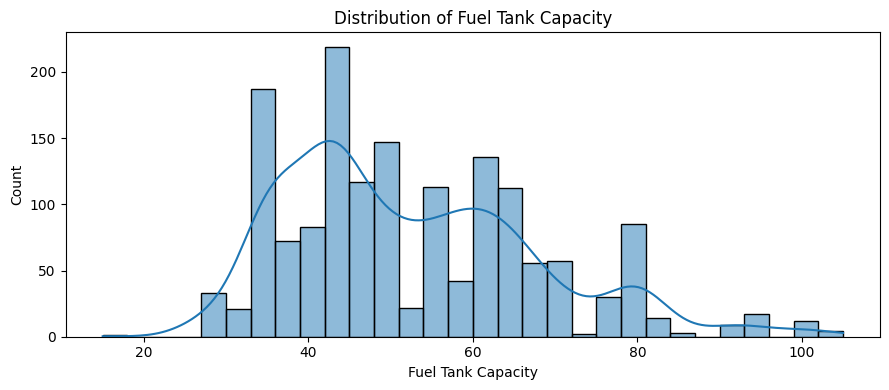

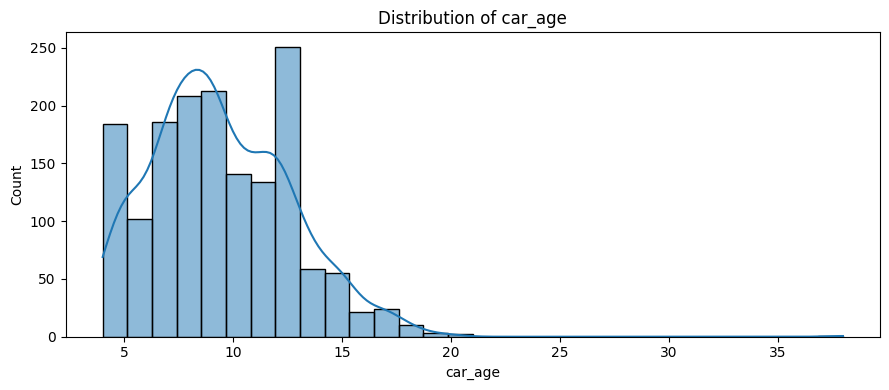

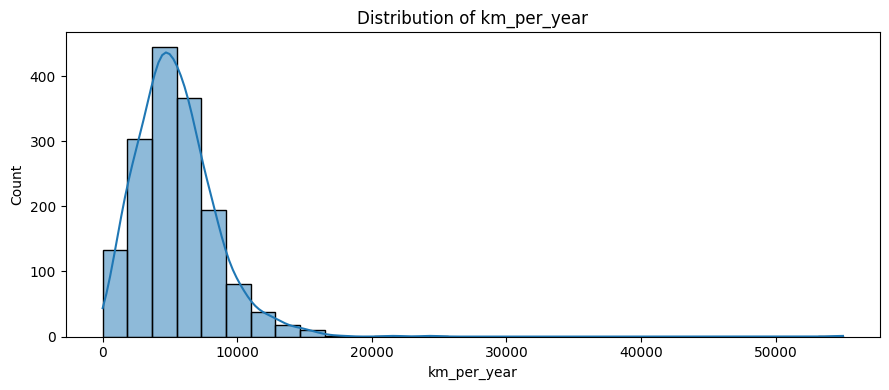

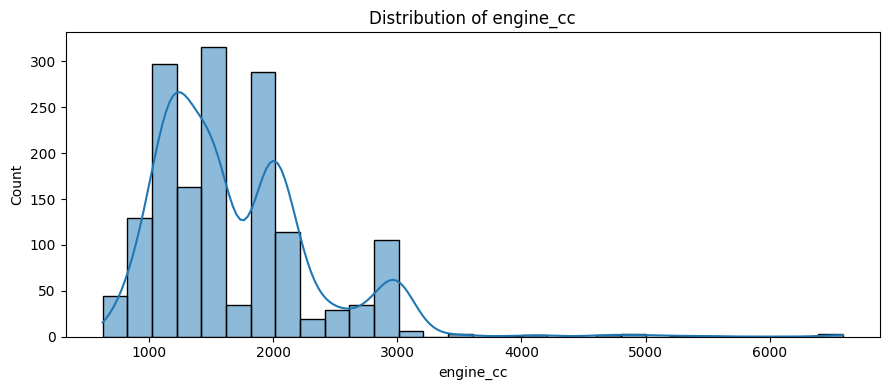

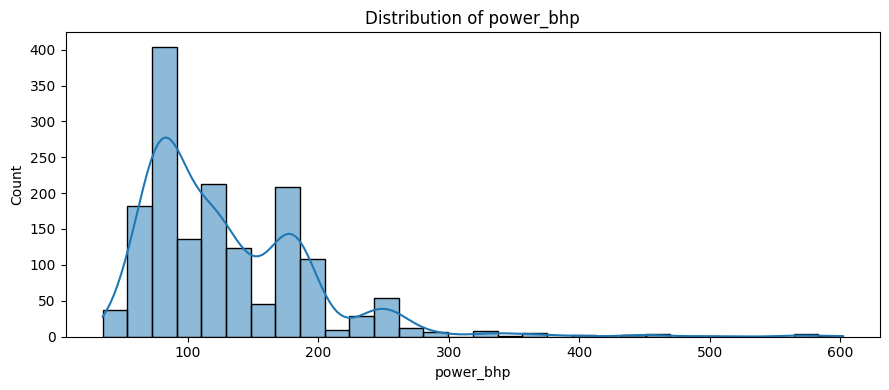

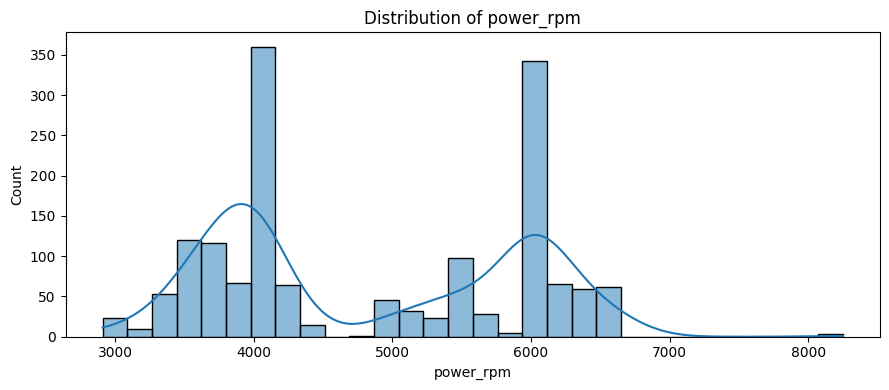

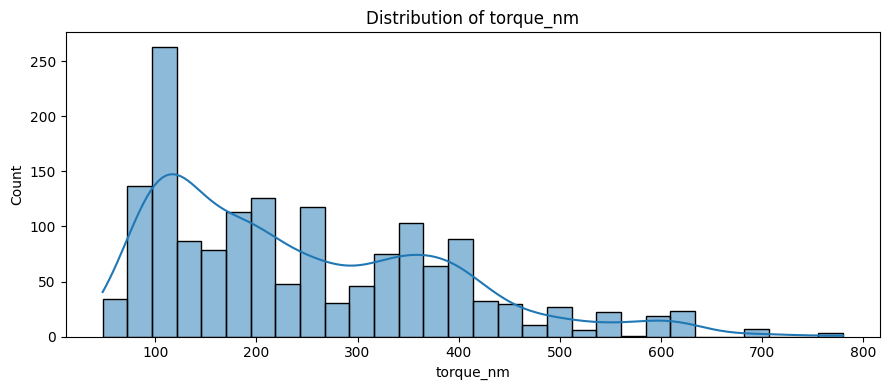

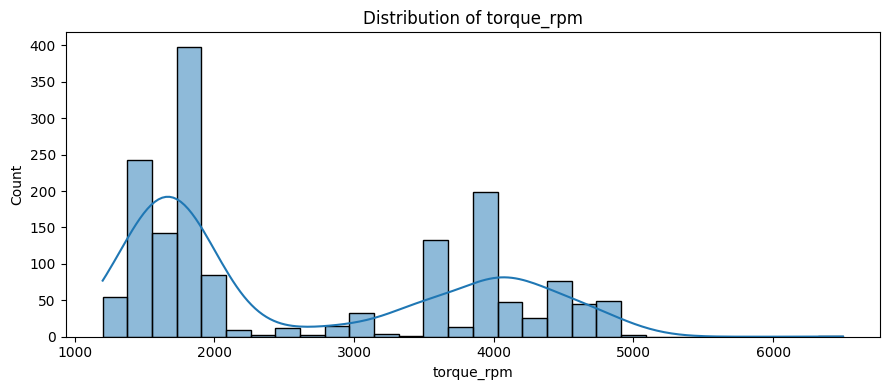

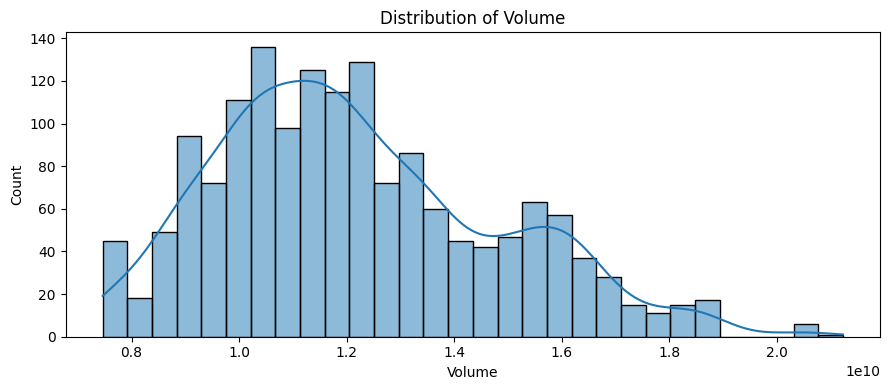

In [41]:
# ============================================================
# Histograms + KDE for all numeric features
# ============================================================
for col in numeric_features:
    plt.figure(figsize=(9, 4))
    sns.histplot(X_train_a[col], bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [42]:
# ============================================================
# IQR-based outlier report per feature
# ============================================================
outlier_rows = []
for col in numeric_features:
    s = X_train_a[col].dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((s < lo) | (s > hi)).sum()

    outlier_rows.append({
        "Feature":         col,
        "Q1":              Q1,
        "Q3":              Q3,
        "Lower_Bound":     lo,
        "Upper_Bound":     hi,
        "Outlier_Count":   int(n_out),
        "Outlier_%":       round(100 * n_out / len(s), 2) if len(s) else 0,
    })

outlier_df = (
    pd.DataFrame(outlier_rows)
    .sort_values("Outlier_%", ascending=False)
)
print("=" * 60)
print("OUTLIER REPORT (IQR method)")
print("=" * 60)
print(outlier_df.round(2).to_string(index=False))

OUTLIER REPORT (IQR method)
           Feature           Q1           Q3   Lower_Bound  Upper_Bound  Outlier_Count  Outlier_%
  Seating Capacity 5.000000e+00 5.000000e+00  5.000000e+00 5.000000e+00            304      19.07
             Width 1.695000e+03 1.835000e+03  1.485000e+03 2.045000e+03            110       6.90
       km_per_year 3.467290e+03 7.000000e+03 -1.831790e+03 1.229907e+04             40       2.51
         Kilometer 2.853075e+04 7.200000e+04 -3.667312e+04 1.372039e+05             30       1.88
         power_bhp 8.300000e+01 1.710000e+02 -4.900000e+01 3.030000e+02             26       1.63
            Height 1.485000e+03 1.675000e+03  1.200000e+03 1.960000e+03             24       1.51
         engine_cc 1.197000e+03 1.995000e+03  0.000000e+00 3.192000e+03             22       1.38
Fuel Tank Capacity 4.200000e+01 6.300000e+01  1.050000e+01 9.450000e+01             18       1.13
            Volume 1.028133e+10 1.364061e+10  5.242420e+09 1.867952e+10             13    

In [43]:
# ============================================================
# Inspect extreme high/low values for top numeric cols
# ============================================================
# For the top 3 outlier features, show the actual rows.
# ============================================================
top_outlier_features = outlier_df.head(3)["Feature"].tolist()

for col in top_outlier_features:
    print(f"\n{'=' * 55}")
    print(f"Top 5 HIGHEST values of: {col}")
    print('=' * 55)
    cols_to_show = [c for c in ["Make", "Model_clean", col]
                    if c in X_train_a.columns]
    display(X_train_a.nlargest(5, col)[cols_to_show])


Top 5 HIGHEST values of: Seating Capacity


,Make,Model_clean,Seating Capacity
436,Mahindra,scorpio s10,8.0
415,Toyota,innova 2.4 vx 8 str,8.0
1992,Toyota,innova 2.0 g1 bs-iv,8.0
1690,Toyota,innova 2.4 vx 8 str,8.0
58,Mahindra,scorpio sle bs-iv,8.0



Top 5 HIGHEST values of: Width


,Make,Model_clean,Width
1313,Land Rover,range rover 3.0 v6 diesel vogue,2220.0
582,Land Rover,range rover 3.0 v6 diesel vogue,2220.0
1305,Land Rover,range rover 3.0 v6 diesel vogue lwb,2220.0
1149,Land Rover,discovery 2.0 hse 4wd diesel,2220.0
216,Mercedes-Benz,r-class r350 4matic,2183.0



Top 5 HIGHEST values of: km_per_year


,Make,Model_clean,km_per_year
1515,Hyundai,creta sx 1.6 at crdi,55000.000000
1991,Toyota,fortuner 2.8 4x4 at,24333.333333
2021,Toyota,fortuner 2.8 4x2 mt,21625.000000
181,Toyota,fortuner 3.0 4x4 mt,17583.333333
1992,Toyota,innova 2.0 g1 bs-iv,16327.250000


Correlation with log1p(Price) (|r| sorted):
power_bhp             0.816
torque_nm             0.812
Width                 0.777
Length                0.770
Fuel Tank Capacity    0.736
Volume                0.728
engine_cc             0.700
torque_rpm           -0.511
car_age              -0.495
power_rpm            -0.423
Kilometer            -0.245
Height                0.177
Seating Capacity      0.103
km_per_year          -0.045


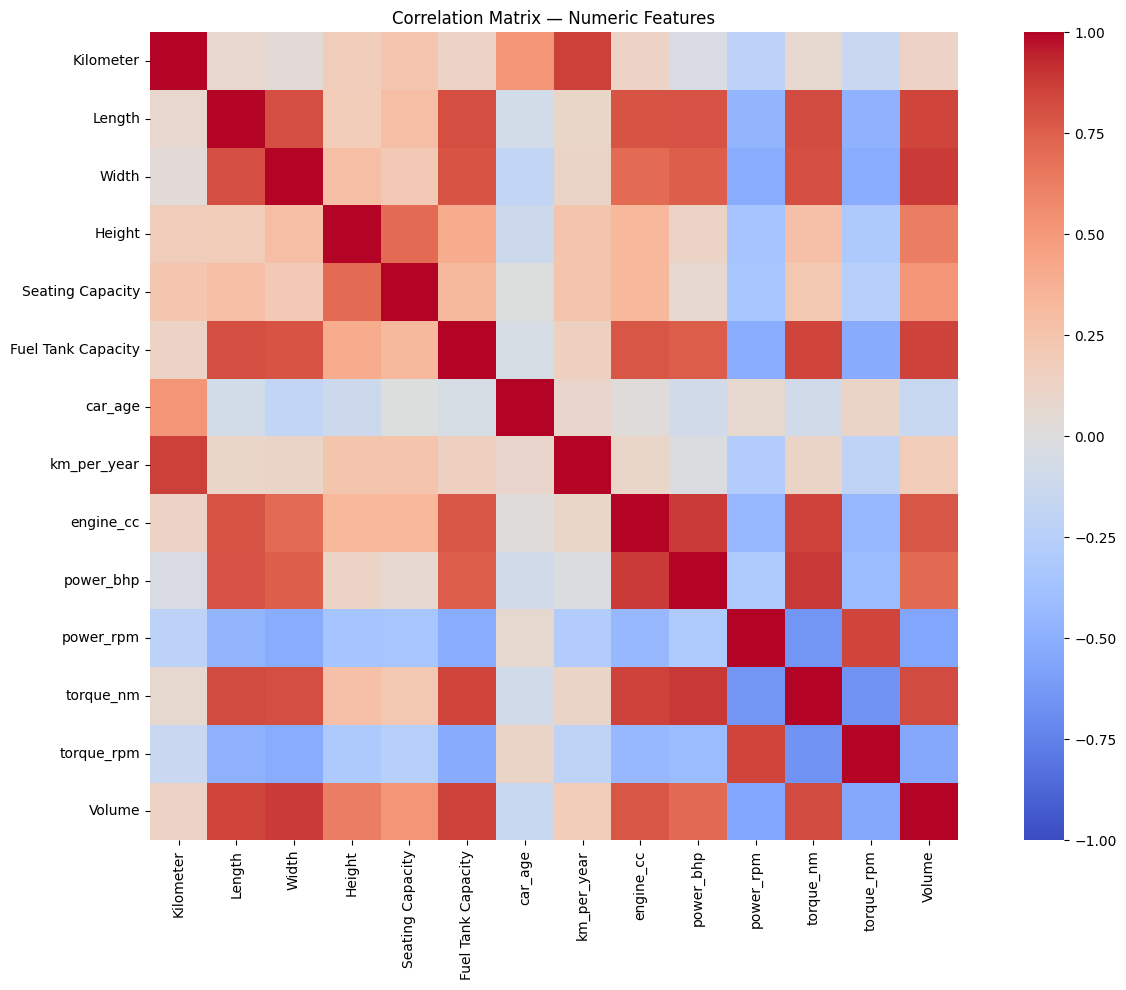


Highly correlated pairs (|r| > 0.8):
  power_bhp                 ↔ torque_nm                  r = +0.884
  engine_cc                 ↔ power_bhp                  r = +0.881
  Width                     ↔ Volume                     r = +0.879
  Kilometer                 ↔ km_per_year                r = +0.863
  Fuel Tank Capacity        ↔ Volume                     r = +0.858
  engine_cc                 ↔ torque_nm                  r = +0.857
  Length                    ↔ Volume                     r = +0.849
  Fuel Tank Capacity        ↔ torque_nm                  r = +0.848
  power_rpm                 ↔ torque_rpm                 r = +0.848
  Length                    ↔ torque_nm                  r = +0.828
  torque_nm                 ↔ Volume                     r = +0.822
  Width                     ↔ torque_nm                  r = +0.819
  Length                    ↔ Fuel Tank Capacity         r = +0.815
  Length                    ↔ Width                      r = +0.813
  Length  

In [44]:
# ============================================================
# Correlation analysis
# 1) Which features correlate most with Price?
# 2) Which features are highly correlated WITH EACH OTHER
#    (multicollinearity → bad for Linear Regression)
# ============================================================
num_features_for_corr = [
    c for c in X_train_a.select_dtypes(include='number').columns
    if c != 'Price'
]

# 1) Correlation with the target (log1p(Price), the scale the model is trained on)
target_corr = (
    X_train_a[num_features_for_corr]
    .corrwith(np.log1p(y_train_a))
    .sort_values(key=abs, ascending=False)
)
print("=" * 55)
print("Correlation with log1p(Price) (|r| sorted):")
print("=" * 55)
print(target_corr.round(3).to_string())

# 2) Correlation heatmap between features
plt.figure(figsize=(14, 10))
sns.heatmap(
    X_train_a[num_features_for_corr].corr(numeric_only=True),
    annot=False, cmap='coolwarm', center=0, vmin=-1, vmax=1,
    square=True
)
plt.title("Correlation Matrix — Numeric Features")
plt.tight_layout()
plt.show()

# 3) Find high-correlation pairs (|r| > 0.8)
corr_m = X_train_a[num_features_for_corr].corr(numeric_only=True)
high_pairs = []
for i in range(len(corr_m.columns)):
    for j in range(i + 1, len(corr_m.columns)):
        r = corr_m.iloc[i, j]
        if abs(r) > 0.8:
            high_pairs.append((corr_m.columns[i], corr_m.columns[j], r))

print("\n" + "=" * 55)
print("Highly correlated pairs (|r| > 0.8):")
print("=" * 55)
for c1, c2, r in sorted(high_pairs, key=lambda x: -abs(x[2])):
    print(f"  {c1:25s} ↔ {c2:25s}  r = {r:+.3f}")

In [45]:
# ============================================================
# VIF (Variance Inflation Factor)
# Measures how much a feature is explained by OTHER features.
# Rule of thumb: VIF > 10 → problematic multicollinearity
# ============================================================
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = X_train_a[num_features_for_corr].dropna()
X_vif = add_constant(X_vif)

vif_df = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i)
            for i in range(X_vif.shape[1])]
})
vif_df = (
    vif_df[vif_df['Feature'] != 'const']
    .sort_values('VIF', ascending=False)
    .reset_index(drop=True)
)
print("=" * 55)
print("VIF (VIF > 10 = problematic):")
print("=" * 55)
print(vif_df.round(2).to_string(index=False))

VIF (VIF > 10 = problematic):
           Feature    VIF
            Volume 193.81
            Length  40.73
            Height  36.20
             Width  29.41
         torque_nm  22.08
         power_bhp  19.77
         Kilometer  16.83
       km_per_year  12.19
         engine_cc   9.08
         power_rpm   8.28
Fuel Tank Capacity   5.30
        torque_rpm   4.59
           car_age   4.58
  Seating Capacity   2.87


## 9. Feature selection

In [46]:
# ============================================================
# Apply the redundant-column drop (REDUNDANT_COLS, section 5.2)
# to the preprocessed data. The same drop is a step inside the
# final pipeline, so raw data can be fed to it directly.
# ============================================================
X_train_sel = drop_redundant_columns(X_train_a)
X_test_sel  = drop_redundant_columns(X_test_a)
print("Dropped:", [c for c in REDUNDANT_COLS if c in X_train_a.columns])
print("Remaining columns:", list(X_train_sel.columns))

Dropped: ['Length', 'Width', 'Height', 'torque_nm', 'engine_cc', 'Kilometer', 'Seating Capacity']
Remaining columns: ['Make', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Drivetrain', 'Fuel Tank Capacity', 'car_age', 'km_per_year', 'power_bhp', 'power_rpm', 'torque_rpm', 'Volume', 'Model_clean']


## 10. Scaler x Encoder search (5-fold CV)

In [47]:
# ============================================================
# Grid search (via 5-fold CV) over
#          {4 scalers} × {4 encoders}
# Result on this dataset:
#   ✓ OHE_drop1: best (R² ≈ 0.84)
#   ✗ TargetEnc / Ordinal: worse
# Note: Standard / Robust / MinMax tie because LinearRegression is invariant to
#       linear rescaling; PowerYJ differs because it is a non-linear transform.
# ============================================================
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)

num_cols = [c for c in X_train_sel.select_dtypes(include='number').columns
            if c != 'Price']
ord_cols = ['Owner'] if 'Owner' in X_train_sel.columns else []
nom_cols = [c for c in ['Make', 'Fuel Type', 'Transmission',
                        'Color', 'Seller Type', 'Drivetrain']
            if c in X_train_sel.columns]

owner_order = [['UnRegistered Car', 'First', 'Second',
                'Third', 'Fourth', '4 or More']]

def build_pipe(scaler, nom_encoder):
    transformers = [
        ('num', Pipeline([('scale', scaler)]), num_cols),
        ('cat', Pipeline([('enc', nom_encoder)]), nom_cols),
    ]
    if ord_cols:
        transformers.append((
            'ord',
            OrdinalEncoder(categories=owner_order,
                           handle_unknown='use_encoded_value',
                           unknown_value=-1,
                           encoded_missing_value=-1),
            ord_cols
        ))
    return Pipeline([
        ('prep', ColumnTransformer(transformers, remainder='drop')),
        ('model', TransformedTargetRegressor(
            regressor=LinearRegression(),
            func=np.log1p, inverse_func=np.expm1
        ))
    ])

scalers = {
    'Standard': StandardScaler(),
    'Robust':   RobustScaler(),
    'MinMax':   MinMaxScaler(),
    'PowerYJ':  PowerTransformer(method='yeo-johnson', standardize=True),
}
encoders = {
    'OHE_drop1': OneHotEncoder(drop='first', sparse_output=False,
                                handle_unknown='ignore'),
    'OHE_full':  OneHotEncoder(drop=None, sparse_output=False,
                                handle_unknown='ignore'),
    'TargetEnc': TargetEncoder(target_type='continuous',
                                smooth='auto', cv=5),
    'Ordinal':   OrdinalEncoder(handle_unknown='use_encoded_value',
                                 unknown_value=-1,
                                 encoded_missing_value=-1),
}

results = []
for (s_name, s_obj), (e_name, e_obj) in product(
    scalers.items(), encoders.items()
):
    pipe = build_pipe(clone(s_obj), clone(e_obj))
    scores = cross_val_score(pipe, X_train_sel, y_train_a,
                              cv=cv5, scoring='r2', n_jobs=-1)
    results.append({
        'Scaler': s_name, 'Encoder': e_name,
        'R2_mean': scores.mean(), 'R2_std': scores.std()
    })
    print(f"{s_name:10s} × {e_name:10s}  "
          f"R2 = {scores.mean():.4f} ± {scores.std():.4f}")

results_df = (
    pd.DataFrame(results)
    .sort_values('R2_mean', ascending=False)
    .reset_index(drop=True)
)
print("\n=== Top 5 ===")
print(results_df.head(5).to_string(index=False))

Standard   × OHE_drop1   R2 = 0.8355 ± 0.0585
Standard   × OHE_full    R2 = nan ± nan
Standard   × TargetEnc   R2 = -0.4195 ± 1.6434
Standard   × Ordinal     R2 = 0.7860 ± 0.0769
Robust     × OHE_drop1   R2 = 0.8355 ± 0.0585
Robust     × OHE_full    R2 = nan ± nan
Robust     × TargetEnc   R2 = 0.3170 ± 0.4932
Robust     × Ordinal     R2 = 0.7860 ± 0.0769
MinMax     × OHE_drop1   R2 = 0.8355 ± 0.0585
MinMax     × OHE_full    R2 = nan ± nan
MinMax     × TargetEnc   R2 = 0.3173 ± 0.4697
MinMax     × Ordinal     R2 = 0.7860 ± 0.0769
PowerYJ    × OHE_drop1   R2 = 0.7649 ± 0.0843
PowerYJ    × OHE_full    R2 = nan ± nan
PowerYJ    × TargetEnc   R2 = 0.7409 ± 0.1288
PowerYJ    × Ordinal     R2 = 0.6540 ± 0.0852

=== Top 5 ===
  Scaler   Encoder  R2_mean   R2_std
  MinMax OHE_drop1 0.835468 0.058509
Standard OHE_drop1 0.835468 0.058509
  Robust OHE_drop1 0.835468 0.058509
  Robust   Ordinal 0.786013 0.076883
Standard   Ordinal 0.786013 0.076883


## 11. Final pipeline: A vs B comparison, evaluation and saving

In [48]:
# ============================================================
# Stage-2 settings + FULL pipeline factory
#   raw data -> preprocess -> drop redundant cols -> Yeo-Johnson
#   -> scaler -> one-hot -> LinearRegression on log1p(Price)
# ============================================================
CAT_COLS = ['Make', 'Fuel Type', 'Transmission', 'Color',
            'Owner', 'Seller Type', 'Drivetrain']
DROP_COLS = ['Model_clean', 'Location']

def make_full_pipeline(drop_rpm=False):
    return Pipeline([
        ("preprocess",  make_preprocess(drop_rpm=drop_rpm)),
        ("select",      FunctionTransformer(drop_redundant_columns, validate=False)),
        ("yeo_johnson", YeoJohnsonTransformer()),
        ("scaler",      NumericScaler(scaler=StandardScaler())),
        ("encoder",     CategoricalEncoder(cat_cols=CAT_COLS, drop_cols=DROP_COLS)),
        ("model",       TransformedTargetRegressor(
                            regressor=LinearRegression(),
                            func=np.log1p, inverse_func=np.expm1)),
    ])

In [49]:
# ============================================================
# Compare A (keep RPM) vs B (drop RPM) with 5-fold CV on RAW train data.
# Imputers / scalers are re-fitted inside every fold -> no leakage.
# ============================================================
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)

variant_scores = {}
for name, drop_rpm in [("A (keep RPM)", False), ("B (drop RPM)", True)]:
    scores = cross_val_score(make_full_pipeline(drop_rpm), X_train_clean, y_train_clean,
                             cv=cv5, scoring="r2", n_jobs=-1)
    variant_scores[name] = (drop_rpm, scores.mean())
    print(f"{name:14s} R2 = {scores.mean():.4f} +/- {scores.std():.4f}")

best_name = max(variant_scores, key=lambda k: variant_scores[k][1])
best_drop_rpm = variant_scores[best_name][0]
print("\nSelected:", best_name)

A (keep RPM)   R2 = 0.7536 +/- 0.0648
B (drop RPM)   R2 = 0.7996 +/- 0.0720

Selected: B (drop RPM)


In [50]:
# ============================================================
#  FINAL MODEL - Linear Regression with log1p target
# ============================================================
# TransformedTargetRegressor trains on log1p(Price) and applies expm1 to the
# predictions, so all metrics below are on the ORIGINAL Price scale.
# The pipeline is fitted on RAW train data and accepts RAW data at predict time.
# ============================================================
final_pipeline = make_full_pipeline(drop_rpm=best_drop_rpm)
final_pipeline.fit(X_train_clean, y_train_clean)

y_pred = final_pipeline.predict(X_test_clean)

print("=" * 55)
print("FINAL TEST EVALUATION (on original Price scale)")
print("=" * 55)
print(f"R2   : {r2_score(y_test_clean, y_pred):.4f}")
print(f"MAE  : {mean_absolute_error(y_test_clean, y_pred):,.0f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_clean, y_pred)):,.0f}")

# Save (to reload it, the custom classes/functions above must be defined first)
joblib.dump(final_pipeline, "car_price_full_pipeline.pkl")
print("\nSaved -> car_price_full_pipeline.pkl")

FINAL TEST EVALUATION (on original Price scale)
R2   : 0.5969
MAE  : 363,819
RMSE : 1,678,136

Saved -> car_price_full_pipeline.pkl


c:\Users\hamas\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## 12. Improving the model (same preprocessing, stronger modelling)

**Diagnosis of section 11.** CV R² is about 0.80 but the test R² is 0.60, and RMSE (1.68M) is 4.6x the MAE (364K). So a *few very expensive cars* dominate the raw-price score. Also, the linear pipeline throws away `Model_clean` and `Location`, and the price depends on age/power in a non-linear way that differs per brand.

**What changes here** (everything in sections 1-9 is reused as-is, including `make_preprocess`):
1. Tree models (Random Forest, HistGradientBoosting) that capture non-linearity and brand interactions.
2. `Model_clean` / `Make` / `Make_Base` / `Location` are target-encoded (cross-fitted, no leakage) instead of being dropped.
3. All numeric features are kept (trees don't suffer from multicollinearity, so no VIF-based dropping).
4. Metrics that are robust to luxury outliers.

In [51]:
from sklearn.compose import make_column_selector
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import cross_validate

In [52]:
# ============================================================
# Extra features ON TOP of the existing preprocessing (row-wise, no leakage)
#   - log_km        : log of Kilometer (the raw column is very skewed)
#   - power_per_cc  : engine efficiency / "sportiness"
#   - Make_Base     : Make + first word of Model  (e.g. "bmw x1"),
#                     a middle level between Make and the ~870 distinct trims
# ============================================================
def add_extra_features(X):
    X = X.copy()
    if "Kilometer" in X.columns:
        X["log_km"] = np.log1p(X["Kilometer"])
    X["power_per_cc"] = X["power_bhp"] / X["engine_cc"].replace(0, np.nan)
    first = X["Model_clean"].astype("string").str.split().str[0].fillna("")
    X["Make_Base"] = (X["Make"].astype("string").str.lower() + " " + first).str.strip()
    return X

In [53]:
# ============================================================
# Improved pipeline (reuses YOUR make_preprocess unchanged)
#   raw -> make_preprocess -> extra features
#       -> [numeric as-is | target-encode high-cardinality | ordinal low-cardinality]
#       -> tree model on log1p(Price)
# Trees don't need scaling / Yeo-Johnson / dropping correlated columns,
# so we keep ALL numeric features here (Kilometer, engine_cc, torque_nm, Length...).
# TargetEncoder is cross-fitted inside fit() -> no target leakage.
# Model_clean and Location are USED here (the linear pipeline dropped them).
# ============================================================
TE_COLS  = ["Make", "Model_clean", "Make_Base", "Location"]
LOW_COLS = ["Fuel Type", "Transmission", "Owner", "Seller Type", "Drivetrain", "Color"]

def make_improved_pipeline(kind="hgb", drop_rpm=True):
    if kind == "rf":
        reg = RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                    n_jobs=-1, random_state=42)
    else:
        reg = HistGradientBoostingRegressor(
            learning_rate=0.05, max_iter=600, max_leaf_nodes=15, min_samples_leaf=15,
            l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
            n_iter_no_change=30, random_state=42)
    encode = ColumnTransformer([
        ("num", "passthrough", make_column_selector(dtype_include="number")),
        ("te",  TargetEncoder(target_type="continuous", cv=5), TE_COLS),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                               encoded_missing_value=-1), LOW_COLS),
    ])
    return Pipeline([
        ("preprocess", make_preprocess(drop_rpm=drop_rpm)),
        ("extra",      FunctionTransformer(add_extra_features, validate=False)),
        ("encode",     encode),
        ("model",      TransformedTargetRegressor(regressor=reg, func=np.log1p,
                                                  inverse_func=np.expm1)),
    ])

In [54]:
# ============================================================
# Metrics that are NOT dominated by a few luxury cars
#   R2_log     : R2 on log(price)  (same scale the model is trained on)
#   MedAPE_%   : median absolute % error  ("typical" error)
#   within_15% : share of cars predicted within +-15% of the real price
# R2_raw / MAE / RMSE are kept so you can compare with section 11.
# ============================================================
def full_report(y_true, y_pred):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    ape = np.abs(y_pred - y_true) / y_true
    return {
        "R2_log":     r2_score(np.log1p(y_true), np.log1p(y_pred)),
        "R2_raw":     r2_score(y_true, y_pred),
        "MAE":        mean_absolute_error(y_true, y_pred),
        "RMSE":       np.sqrt(mean_squared_error(y_true, y_pred)),
        "MedAPE_%":   100 * np.median(ape),
        "within_15%": 100 * (ape <= 0.15).mean(),
    }

### 12.1 Linear (yours) vs improved models

In [55]:
# ============================================================
# Compare: your linear pipeline vs the improved tree models
# Same train rows, same test rows, same preprocessing code.
# ============================================================
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
r2_log_scorer = lambda est, X_, y_: r2_score(np.log1p(y_), np.log1p(est.predict(X_)))

candidates = {
    "Linear (section 11)": final_pipeline,                       # already fitted above
    "Random Forest":       make_improved_pipeline("rf",  drop_rpm=True),
    "HistGradientBoosting": make_improved_pipeline("hgb", drop_rpm=True),
}
rows, fitted = {}, {}
for name, pipe in candidates.items():
    if name != "Linear (section 11)":
        pipe.fit(X_train_clean, y_train_clean)
    cv_r2 = cross_validate(clone(pipe), X_train_clean, y_train_clean, cv=cv5,
                           scoring=r2_log_scorer, n_jobs=-1)["test_score"].mean()
    rows[name] = {**full_report(y_test_clean, pipe.predict(X_test_clean)), "CV_R2_log": cv_r2}
    fitted[name] = pipe

results = pd.DataFrame(rows).T
display(results.round(3))

c:\Users\hamas\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,R2_log,R2_raw,MAE,RMSE,MedAPE_%,within_15%,CV_R2_log
Linear (section 11),0.942,0.597,363819.002,1678136.178,13.113,55.340,0.934
Random Forest,0.965,0.751,289862.645,1320087.131,9.699,69.175,0.948
HistGradientBoosting,0.963,0.648,268043.938,1567820.696,8.765,75.000,0.957


### 12.2 Error analysis

Best model: Random Forest


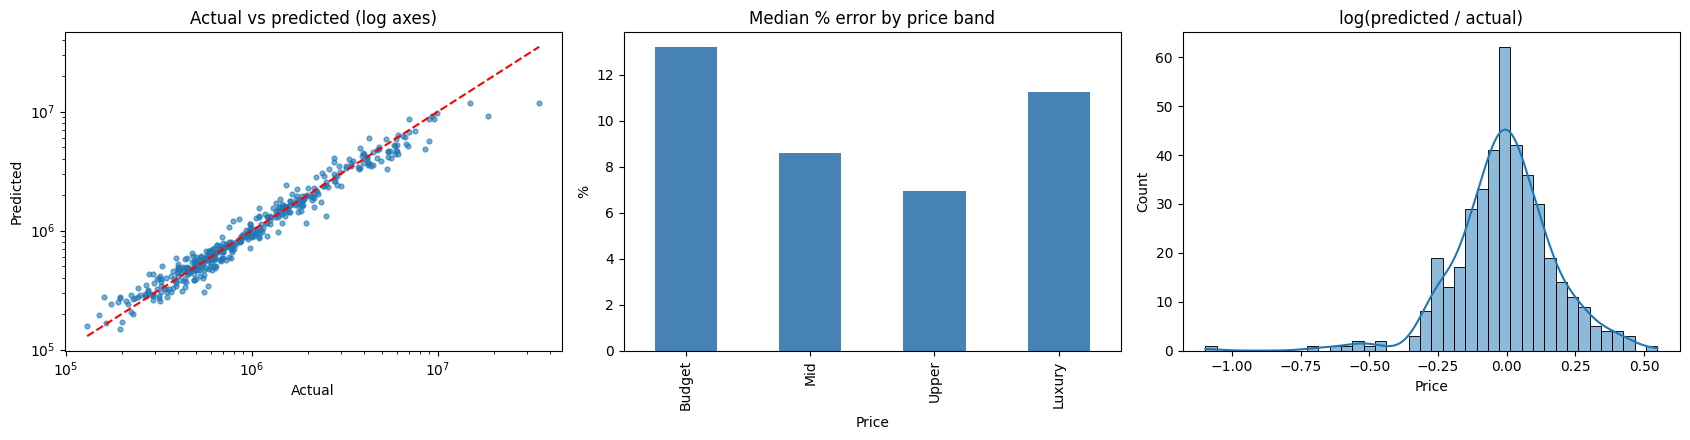

,Make,Model,Year,Actual,Predicted,Error_pct
1978,Maruti Suzuki,Ritz Ldi BS-IV,2011,160000,276762.0,73.0
483,Ferrari,488 GTB,2018,35000000,11694148.0,-66.6
1607,Audi,A3 35 TDI Technology + Sunroof,2016,1525000,2407747.0,57.9
873,Renault,Duster 85 PS RxL Diesel,2013,280000,435738.0,55.6
881,Maruti Suzuki,Eeco 5 STR WITH A/C+HTR [2019-2020],2018,328000,507614.0,54.8
1041,Skoda,Superb Elegance 1.8 TSI AT,2014,795000,1207217.0,51.9
599,Renault,Fluence 1.5 E4,2013,390000,588331.0,50.9
1912,Mercedes-Benz,S-Class S 350D [2018-2020],2021,18500000,9151536.0,-50.5
2044,Mahindra,XUV700 AX 7 Petrol AT Luxury Pack 7 STR,2022,2765000,4077061.0,47.5
1646,Tata,Hexa XM 4x2 7 STR,2018,850000,1251949.0,47.3


In [56]:
# ============================================================
# Error analysis of the best model
# ============================================================
best_name  = results["R2_log"].idxmax()
best_model = fitted[best_name]
pred = best_model.predict(X_test_clean)
actual = y_test_clean
print("Best model:", best_name)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(actual, pred, s=12, alpha=.6)
lim = [actual.min(), actual.max()]; ax[0].plot(lim, lim, "r--")
ax[0].set(xscale="log", yscale="log", title="Actual vs predicted (log axes)",
          xlabel="Actual", ylabel="Predicted")

band = pd.qcut(actual, 4, labels=["Budget", "Mid", "Upper", "Luxury"])
((np.abs(pred - actual) / actual).groupby(band, observed=True).median() * 100
 ).plot.bar(ax=ax[1], color="steelblue")
ax[1].set(title="Median % error by price band", ylabel="%")

sns.histplot(np.log(pred / actual), bins=40, kde=True, ax=ax[2])
ax[2].set_title("log(predicted / actual)")
plt.tight_layout(); plt.show()

worst = X_test_clean.assign(Actual=actual, Predicted=pred.round(0),
                            Error_pct=(100 * (pred - actual) / actual).round(1))
display(worst.reindex(worst["Error_pct"].abs().sort_values(ascending=False).index)
        [["Make", "Model", "Year", "Actual", "Predicted", "Error_pct"]].head(10))

### 12.3 Save

In [57]:
# ============================================================
# Refit the best pipeline on ALL available rows and save it
# (accepts RAW data, like the pipeline in section 11)
# ============================================================
X_all = pd.concat([X_train_clean, X_test_clean]); y_all = pd.concat([y_train_clean, y_test_clean])
deploy_model = clone(candidates[best_name]).fit(X_all, y_all)
joblib.dump(deploy_model, "car_price_best_pipeline.pkl")
print("Saved -> car_price_best_pipeline.pkl")

Saved -> car_price_best_pipeline.pkl


## Conclusion
- Section 11 (Linear): test R² 0.597 on raw price, MAE 363,819.
- Section 12: write the new numbers from the table above (R²_log, MedAPE %, within 15%).
- Next ideas: `RandomizedSearchCV` on HGB, SHAP explanations, separate models for the luxury segment.